<!-- repo-header -->
# SSO with a chi=4 disentangler  *(exploratory)*

Early exploration of Schmidt Spectrum Optimisation using a **chi = 4** disentangling
layer instead of the chi = 2 staircase used everywhere else in the thesis.

This notebook produced no thesis figure. It is kept because it is where the
staircase cost function and the disentangling loop were first worked out, and it
documents why chi = 2 was chosen: the chi = 2 staircase is the largest bond
dimension that Ran's analytic construction can encode *exactly* in one layer of
two-qubit gates, so it trades extra layers for exactness rather than approximating
each layer.

**Start at `01_sso_preparation.ipynb` instead** if you only want the method used in
the thesis.


# Archie's Schmidt Spectra Optimiser with Chi 4 Disentangling Layers.

## Original Algorithm and my additions

In [1]:
import quimb.tensor as qtn
import quimb as qu
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from math import cos, sin, pi
from autoray import do
from scipy.linalg import qr, null_space
from typing import Dict, List, Tuple, Optional
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from collections import Counter
import autoray as ar
import jax.numpy as jnp
from skimage import data
from skimage.transform import resize
from scipy.stats import unitary_group
#import geoopt
#import geotorch
import math
import torch
import torch.nn as nn
from torch.nn.utils import parametrize

from functools import partial

'''This is the contraction method for the tensor networks ie For all future tensor contractions, automatically search for a high-quality contraction path (using a slower but smarter optimizer), so that contractions run efficiently on large networks '''
qtn.set_contract_strategy('auto-hq')

import mps_to_circuit as mtc
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator


''' This allows us to get the information from the qiskit circuit '''
def get_qiskit_gate_info(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for ci in qc.data:                      # ci is a CircuitInstruction
        instr = ci.operation                # was: instr
        qargs = ci.qubits                   # was: qargs
        qubits = [qc.find_bit(q).index for q in qargs]

        try:
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")

    return gates


'''Ensures the indicies of the TN are lrp'''
def ensure_mps_shape_lrp(mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Return a copy of `mps` whose site tensors have a consistent axis order:
      - interior sites: (vL, vR, p)
      - left edge:      (vR, p)
      - right edge:     (vL, p)

    This is the default 'lrp' format used by quimb.
    """
    mps = mps.copy()
    N = mps.L

    for i in range(N):
        T = mps[i]
        p = mps.site_ind(i)
        # all non-physical indices on this site
        virt = [ix for ix in T.inds if ix != p]

        if i == 0:
            # left edge: single virtual = vR
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vR = virt[0]
            T.transpose(vR, p, inplace=True)

        elif i == N - 1:
            # right edge: single virtual = vL
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vL = virt[0]
            T.transpose(vL, p, inplace=True)

        else:
            # interior: two virtuals; identify left vs right by neighbor sharing
            assert len(virt) == 2, f"Site {i} expected 2 virtual legs, found {len(virt)}."
            left_neighbor_inds = set(mps[i - 1].inds)
            right_neighbor_inds = set(mps[i + 1].inds)

            # the bond shared with the left/right neighbor
            vL = next(ix for ix in virt if ix in left_neighbor_inds)
            vR = next(ix for ix in virt if ix in right_neighbor_inds)

            T.transpose(vL, vR, p, inplace=True)

    return mps


'''Make the circuit in qiskit then map to quimb'''
def mps_to_circuit_quimb(mps: qtn.MatrixProductState) -> qtn.Circuit:
    """ Functionality thanks to https://github.com/qiskit-community/mps-to-circuit. MPS must have shape (vL,vR, phys) unless shape is specified. """
    
    psi = ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)

    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]

    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp',method='exact')

    gates_info = get_qiskit_gate_info(qiskit_qc)

    qc = qtn.Circuit(mps.L)
   
    for gate in gates_info:
        name, qubits, U = gate
        qubits.reverse()
        qc.apply_gate(U, *qubits)

    return qc

"""def optimise_to_zero(n: int,eps: float = 1e-2):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    
    to_opt = qc.uni

    targ_qc = qtn.Circuit(n)
    I4 = qu.eye(4)  # two-qubit identity (4×4)
    for i in range(n - 1): targ_qc.apply_gate(I4, i, i + 1, tags=['SU4'])
    targ_uni = targ_qc.uni 

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ_uni},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    #opt_uni = tnopt.optimize_basinhopping(n=600,tol=1e-14,nhop=100)

    params = opt_uni.get_params()

    return params"""


'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_identity(eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(np.eye(4).reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    return params


'''Gives the paramters of a complete unity circuit not just a gate'''
def optimise_to_zero(n: int,eps: float = 1e-2):
    params = optimise_su4_gate_to_identity(eps=eps)[2]
        
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params


'''Gives the parameterised identity circ'''
def near_zero_parametrized_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised near-identity """

    #params = optimise_to_zero(n)
    params = GLOBAL_IDENTITY_LAYER_PARAMS ###--what is this????
    qc = qtn.Circuit(n)
    #for idx in range(n-1):
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc

'''Using the optimised identity params this becomes an idenity circuit layer'''
def parametrized_circ_layer(n: int, params: np.ndarray, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised with params. """
    qc = qtn.Circuit(n)
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc


'''Computes the Schmidt coefficients (or their squares, i.e. entanglement spectrum) for a bipartition of a quantum state, given the left and right Gram matrices'''
'''def schmidt_from_gram(L,R,square: bool = True, cut_zeros: bool = True) -> torch.Tensor:
    L = (L + L.conj().T) / 2
    R = (R + R.conj().T) / 2

    # 2) eigensqrt of L
    w, U = torch.linalg.eigh(L)
    w = torch.clip(w, 0, None)
    Lh = (U * torch.sqrt(w)[None, :]) @ U.conj().T

    # 3) build A and solve
    A = Lh @ R @ Lh
    A = (A + A.conj().T) / 2
    mu = torch.linalg.eigvalsh(A)
    mu = torch.clip(mu.real, 0, None)

    # Schmidt coefficients
    s = torch.sqrt(mu).flip(0)

    if square:
        s = s**2

    if cut_zeros:
        s = s[s > 1e-14]
        
    return s'''
import torch
from typing import Tuple, Optional

def schmidt_from_gram(
    L: torch.Tensor,
    R: torch.Tensor,
    square: bool = True,
    cut_zeros: bool = True,
    *,
    eps_abs: float = 1e-16,
    eps_rel: float = 1e-12,
    cond_limit: float = 1e10,
    jitter: float = 1e-8,
    return_info: bool = False,
) -> torch.Tensor:
    """
    Compute Schmidt coefficients from Gram matrices L, R in a numerically robust way.

    L, R: (..., N, N) complex or real tensors. Supports batching.
    eps_abs: absolute minimum eigenvalue (very tiny floor).
    eps_rel: relative floor as a fraction of the max eigenvalue per matrix.
    cond_limit: maximum allowed condition number ~ max_eig / min_allowed_eig.
                If cond_limit is finite, min_allowed_eig = max(max_eig/cond_limit, eps_rel*max_eig, eps_abs)
    jitter: extra additive jitter to the diagonal (useful to force PD for cholesky; typically 0).
    return_info: if True returns (s, info_dict) where info_dict contains diagnostics.

    Returns:
      s: Schmidt coefficients (descending), optionally squared if square=True and filtered if cut_zeros=True.
    """
    # 0) basic checks and symmetrize
    if L.shape[-2] != L.shape[-1] or R.shape[-2] != R.shape[-1]:
        raise ValueError("L and R must be square matrices (..., N, N).")
    if L.shape[-2] != R.shape[-2]:
        raise ValueError("L and R must be same size.")
    if not torch.isfinite(L).all() or not torch.isfinite(R).all():
        raise ValueError("L or R contains NaN/Inf.")
    
    # Hermitize (works for complex data too)
    herm = lambda X: (X + X.conj().transpose(-2, -1)) / 2
    L = herm(L)
    R = herm(R)

    # Optionally add tiny jitter first (keeps reconstruction stable)
    if jitter > 0:
        N = L.shape[-1]
        eye = torch.eye(N, device=L.device, dtype=L.dtype)
        L = L + jitter * eye

    # eigendecompose L
    # PREVIOUS 06/11
    '''w, U = torch.linalg.eigh(L)   # w: (..., N) ascending order by torch convention

    # diagnostics
    max_w = w.amax(dim=-1, keepdim=True)   # (..., 1)
    max_w_safe = torch.clamp(max_w, min=1e-30)  # avoid divide-by-zero
    # compute allowed minimum eigenvalue per matrix (batched)
    min_allowed = torch.maximum(
        torch.full_like(max_w_safe, eps_abs),
        torch.maximum(eps_rel * max_w_safe, max_w_safe / cond_limit)
    )  # (..., 1)

    # clamp eigenvalues (relative threshold)
    w_clamped = torch.clamp(w, min=min_allowed.squeeze(-1))

    # optional info
    num_clamped = (w < w_clamped).to(torch.int64).sum(dim=-1)  # count per batch
    frac_clamped = num_clamped.to(torch.get_default_dtype()) / w.shape[-1]

    # build sqrt(L) = U diag(sqrt(w_clamped)) U^†
    sqrt_w = torch.sqrt(w_clamped)
    # broadcasting: (.., N) -> (.., 1, N) for left-multiplication on U
    Lh = (U * sqrt_w.unsqueeze(-2)) @ U.conj().transpose(-2, -1)


    # construct A and symmetrize
    A = Lh @ R @ Lh
    A = herm(A)'''

    # ----- NEW: Cholesky-based "square root" (no eigenvectors; phase-safe) -----
    # We already hermitized L above and added optional jitter.
    # Make sure L is PD enough for Cholesky by adapting jitter if needed.
    def chol_with_adaptive_jitter(M: torch.Tensor, base_jitter: float):
        N = M.shape[-1]
        eye = torch.eye(N, device=M.device, dtype=M.dtype)
        jitter = base_jitter
        for _ in range(6):  # try a few times, up to ~1e-6 if starting at 1e-12
            try:
                return torch.linalg.cholesky(M + (jitter * eye)), jitter
            except RuntimeError:
                jitter = max(jitter * 10.0, 1e-12) if jitter > 0 else 1e-12
        # final attempt with cholesky_ex to get info
        C, info = torch.linalg.cholesky_ex(M + (jitter * eye))
        if (info > 0).any():
            raise RuntimeError("Cholesky failed: L not PD even after jitter.")
        return C, jitter

    C, used_jitter = chol_with_adaptive_jitter(L, jitter)

    # Build A = C^H R C (Hermitian if R is Hermitian); this is
    # unitarily similar to L^{1/2} R L^{1/2} so it has the same eigenvalues.
    A = C.conj().transpose(-2, -1) @ R @ C
    A = (A + A.conj().transpose(-2, -1)) / 2  # re-hermitize numerically

    # eigenvalues of A (real, ascending)
    mu = torch.linalg.eigvalsh(A)
    # numerical safety: clamp small negatives to zero
    mu = torch.clip(mu.real, 0.0, None)

    # Schmidt coefficients: sqrt(mu) in descending order
    s = torch.sqrt(mu).flip(-1)

    if square:
        s = s**2

    if cut_zeros:
        # flatten last dimension and cut tiny entries
        # we'll return per-batch concatenated tensors, so handle batch case by converting to list
        out_list = []
        if s.ndim == 1:
            out_list = [s[s > 1e-14]]
        else:
            # batch handling: return a list of 1D tensors (one per batch)
            # but to keep same return type as before (tensor) we'll concatenate if batch size == 1,
            # otherwise return list if multiple batches (safer).
            batch_shape = s.shape[:-1]
            s_reshaped = s.reshape(-1, s.shape[-1])  # (B, N)
            for row in s_reshaped:
                out_list.append(row[row > 1e-14])
            if s_reshaped.shape[0] == 1:
                s = out_list[0]
            else:
                # when multiple batches present, return a list of tensors (doable) or pad to rectangular array.
                # Here we return a list for explicitness.
                if return_info:
                    info = {
                        "num_clamped": num_clamped,
                        "frac_clamped": frac_clamped,
                        "w_max": max_w.squeeze(-1),
                        "min_allowed": min_allowed.squeeze(-1),
                    }
                    return out_list, info
                return out_list

    if return_info:
        info = {
            "num_clamped": num_clamped,
            "frac_clamped": frac_clamped,
            "w_max": max_w.squeeze(-1),
            "min_allowed": min_allowed.squeeze(-1),
        }
        return s, info

    return s


'''Contruct the left and right contracted tensors so we are only looking at the required bypartition'''
def construct_L_R_Gram_matrices(tn: qtn.TensorNetwork, ind: str, *, device=None, dtype=None) -> qtn.TensorNetwork:
    """ Construct L_a,a' and R_a,a' Gram matrices. """
    ket = tn.copy()
    bra = ket.copy().conj()
    bra.reindex_({i: i + '_bra' for i in bra._inner_inds})

    comb = (bra|ket)

    #Find relevant tags of border tensors
    tidL, tidR = comb.ind_map[ind]
    L_tag = [tag for tag in comb.tensor_map[tidL].tags if tag.startswith('I')]
    R_tag = [tag for tag in comb.tensor_map[tidR].tags if tag.startswith('I')]
    if len(L_tag)!=1 or len(R_tag)!=1:
        print(comb)
        print(L_tag)
        print(R_tag)
    assert len(L_tag)==1 and len(R_tag)==1, "Tensors in combined TN should have unique identifying tag"
    L_tag = L_tag[0]
    R_tag = R_tag[0]

    L_tag_id = int(str(L_tag[1:]))
    R_tag_id = int(str(R_tag[1:]))

    L_tag = f'I{min(L_tag_id,R_tag_id)}'
    R_tag = f'I{max(L_tag_id,R_tag_id)}'
    assert R_tag_id > L_tag_id, "Right border unique tag should be greater than the left border unique tag"

    L_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])<=L_tag_id]
            
    R_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])>=R_tag_id]
    
    #Form subnetworks and contract
    L_subnetwork = comb.select(L_tags,which='any')
    R_subnetwork = comb.select(R_tags,which='any')

    output_inds = (ind, ind+'_bra')
    L_contracted = L_subnetwork.contract(all,output_inds=output_inds,backend='torch')
    R_contracted = R_subnetwork.contract(all,output_inds=output_inds,backend='torch')

    L_mat = L_contracted.data
    R_mat = R_contracted.data

    return L_mat, R_mat


'''Cumulated the above two functions as to find the scmidt coeffs'''
'''def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    s = schmidt_from_gram(L_mat,R_mat)
    return s'''

def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    # 2) Compute Schmidt coefficients using safe numerical parameters
    s = schmidt_from_gram(
        L_mat,
        R_mat,
        square=True,
        cut_zeros=True,
        eps_abs=1e-16,     # absolute floor
        eps_rel=1e-12,     # relative floor
        cond_limit=1e10,   # cap condition number
        jitter=1e-12,      # tiny diagonal regularization
        return_info=False, # only return s
    )
    return s



'''Is the code to apply the circuit to the mps ie does the contractions'''
def apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        print(t.inds)
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))

    if gauge:
        new.gauge_all(method='simple',inplace=True)
    
    """to_split = new.tensors[-1]
    num_phys = [i for i in to_split.inds if i.startswith('b')]
    if len(num_phys)>1:
        left_phys_idx = new.L-2
        virt = [i for i in to_split.inds if not i.startswith('b')][0]
        TL,TR = to_split.split(
            left_inds=(f'b{left_phys_idx}',virt),
            right_inds=(f'b{left_phys_idx+1}'),
            method='svd',
            absorb='both'
        )

        TL.add_tag(f"I{left_phys_idx}")
        TR.drop_tags()
        TR.add_tag(f"I{left_phys_idx+1}")
        new = qtn.TensorNetwork([new.tensors[:-1],TL,TR])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)"""

    return new
    #return ensure_mps_shape_lrp(new)

'''This is the same functinality as the above but might do it in a slightly differnt way'''
def apply_single_layer_to_mps(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    bL = f'b{mps.L-2}'
    bR = f'b{mps.L-1}'
    T = next(T for T in new.tensors if bL in T.inds and bR in T.inds)
    virt, = [ind for ind in T.inds if ind not in (bL,bR)]
    
    kept = []
    for t in new:
        if bL not in t.inds and bR not in t.inds:
            kept.append(t)
    
    TL,TR = T.split(
        left_inds=(bL,virt),
        right_inds=(bR,),
        method='svd',
        absorb='right'
    )
    
    ordered_list = []
    idx = 0
    while idx < mps.L:
        for t in kept+[TL,TR]:
            for ind in t.inds:
                if ind[0]=='b':
                    id = int(ind[1:])
                    if idx == id:
                        ordered_list.append(t)
                        break
        idx+=1

    new = qtn.TensorNetwork(ordered_list)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    
    for idx,t in enumerate(new):
        t.modify(tags=(f"I{idx}"))        
        if t.ndim==3:
            if f'k{new.L-2}' in t.inds:
                a,b,c = t.inds
                new_ind_ordering = (b,c,a)
                t.transpose(*new_ind_ordering, inplace=True)
            else:
                a,b,c = t.inds
                new_ind_ordering = (c,b,a)
                t.transpose(*new_ind_ordering, inplace=True)

    return new

def ordered_mps(tn: qtn.MatrixProductState):
    tn = tn.copy()
    tensors = []
    num_added = 0
    while num_added < tn.L:
        for t in tn:
            if f'k{num_added}' in t.inds:
                tensors.append(t)
                num_added+=1
                if f'k{num_added}' in t.inds:
                    num_added+=1
                break
    new = qtn.TensorNetwork(tensors)
    new.view_as(qtn.MatrixProductState, inplace=True, L=tn.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    return new


'''This applies the adjoint of the circuit we give to the mps'''
def apply_single_layer_to_mps(circ_tn: qtn.Circuit, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """ 
    
    Contract a circuit layer MPO with an MPS, reshaping it into an MPS form.

    Provide the circuit for which the adjoint is applied.
    
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #circ_tn.reindex({f'b{x}': f't{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f'k{x}': f'b{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f't{x}': f'k{x}' for x in range(mps.L)},inplace=True)

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)
    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)

    if new.max_bond()==1:
        return new
    
    new.full_simplify(seq='ADCR',atol=0.0,inplace=True)
    
    new = ordered_mps(new)
    
    current_idx = 0
    last_tensor_inds = ()
    while current_idx < new.L:
        T = new.tensors[current_idx].copy()

        phys_inds = np.array([i for i in T.inds if i[0]=='k'])

        if len(phys_inds) == 1:
            last_tensor_inds = T.inds
            current_idx+=1 
            continue

        current_phys = f'k{current_idx}'
        left_inds = [i for i in T.inds if i in last_tensor_inds]
        left_inds = tuple(left_inds + [current_phys])

        if current_idx == mps.L-2:
            left_inds = tuple([i for i in T.inds if i != f'k{current_idx+1}'])
        
        right_inds = tuple([i for i in T.inds if i not in left_inds])
        
        #print(f'current phys = {current_phys}. left inds = {left_inds}. right inds = {right_inds}. All inds = {T.inds}. Prev inds = {last_tensor_inds}.')
        TL,TR = qtn.tensor_split(T, left_inds=left_inds, method='svd', absorb='left', cutoff=1e-14)

        new = qtn.TensorNetwork(new.tensors[:current_idx] + (TL,TR) + new.tensors[current_idx+1:])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
                
        last_tensor_inds = left_inds
        current_idx+=1

    for t in new:
        for i in t.inds:
            if i[0]=='k':
                idx = i[1:]
        t.modify(tags = {f'I{idx}'})

    new.compress(cutoff=1e-16)
    new.left_canonicalize(inplace=True)

    new_inds = (new.tensors[-1].inds[1],new.tensors[-1].inds[0])
    new.tensors[-1].transpose(*new_inds,inplace=True)
    new = ensure_mps_shape_lrp(new)

    return new


'''THis functions shows the fidelity of a chi = bond approximation of the MPS'''
def test_bond_accuracy(tn,bond):
    tn = tn.copy()
    x = tn.copy()
    x.compress(max_bond=bond)
    x/=x.norm()
    return abs((x.conj() | (tn / tn.norm())).contract(all))**2


'''ALLL BELOW ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''This function defines the loss function for the optimisation of layers, op = circuit, intit_tn = intial mps'''
'''def torch_schmidt_loss_fn(op: qtn.TensorNetwork, init_tn: qtn.MatrixProductState, target_bond_dim: int = 1, gamma: float = 4.0, alpha: float = 0.2) -> torch.Tensor:
    """
    C(lambda) = sum(w_i*lambda_i) + alpha (1 - sum(lambda_i^2)) + beta * RELU(m - (lambda_D - lambda_(D+1))) = tail mass + alpha*linear entropy + beta*gap penalty. w_i = (i-D)^gamma. D = target_bond_dim.
    """
    init_tn = init_tn.copy()
    op = op.copy()
    #op.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)#here we contact the mps with the circuit
    
    vals = []
    for ind in new_tn.inner_inds():
        schmidt_coeffs = schmidt_coeffs_from_ind(new_tn,ind)

        tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
        idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
        weights = idx**gamma

        C_tail_mass = (weights * tail).sum()
        #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

        loss = C_tail_mass #+ alpha*C_lin_entropy
        vals.append(loss)

    vals = torch.stack(vals)

    return vals.sum()'''

'''This is the entanglement as the loss function'''
'''def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = torch.finfo(torch.float64).tiny  # ~2e-308
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0
        p = p / (p.sum() + eps)                                        # normalize
        Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0:
            Tj = 1.0 - (p[0] + p[1] + p[2] + p[3]) ###FIND ME HERE #Immediate compressibility proxy
            Cj = (1.0-g)*Sj + g*Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum() 

import math'''

def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = 1e-12
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0, p_i =  λ_i^2
        
        d = p.numel()
        if d== 0:
            continue
        p = torch.clamp(p, min=0.0)

        p = p / p.sum()

        # --- Entropy (use change-of-base to avoid log2 instability under AMP) ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        
        #ADDED NORMALISATION
        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max #normalise in [0,1] 

        #Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0: #1-(p_1^2+p_2^2) 
            #print(len(p))
            #print(p.numel())
            topk = min(2, p.numel())
            Tj = 1.0 - p.narrow(0, 0, topk).sum()
            Cj = (1.0 - g) * Sj + g * Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum()

def new_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.5,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=2 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2)                   # tail mass (chi=2 infidelity)
      r_i      = p_i / T_j for i >= 3             # tail distribution (if T_j > 0)
      H_tail   = -sum_{i>=3} r_i log2 r_i         # entropy of tail
      H_tail_n = H_tail / log2(d_tail) in [0,1]   # d_tail = len(tail), if >= 2

    Per-cut cost:
      C_j(g) = T_j * (1 + g * H_tail_n)

    - T_j drives you towards high chi=2 fidelity.
    - H_tail_n only cares about *how messy the tail is*.
    - g in [0,1] controls how much you value "cleaning up / structuring the tail"
      vs purely greedy chi=2.

    When T_j -> 0, C_j -> 0 regardless of H_tail_n, so late stages are effectively greedy.
    """
    # clamp g to [0, 1]
    #g = float(max(0.0, min(1.0, g)))

    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ^2 already
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if lam2.numel() == 0:
            continue

        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
        d = p_sorted.numel()

        if d <= 2:
            # no tail -> already rank<=2 across this cut
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        # chi=2 tail mass
        topk = 2
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        tail = p_sorted[topk:]          # shape (d_tail,)
        d_tail = tail.numel()

        if d_tail <= 1:
            # a single tail mode still present: no entropy structure
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            # tail distribution r_i = p_i / T_j
            r = tail / Tj
            r = torch.clamp(r, min=eps)

            H_tail = - (r * (r.log() / math.log(2.0))).sum()
            H_max = math.log2(d_tail)
            H_tail_norm = H_tail / H_max

        # multiplicative planning: penalise large & messy tails
        Cj = Tj * (1.0 + g * H_tail_norm)
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()


def loss_renyi2_sum(op, init_tn):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    total = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        total = total - torch.log2((p*p).sum().clamp_min(1e-300))  # Σ_j S2^(j)
    return total

def loss_smoothmax_entropy(op, init_tn, tau=0.1):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        S = -(p * torch.log2(p.clamp_min(1e-12))).sum()
        vals.append(S)
    vals = torch.stack(vals)
    return tau * torch.logsumexp(vals / tau, dim=0)

def loss_weighted_tail(op, init_tn, D=4, gamma=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    tot = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        tail = p[D:]
        if tail.numel():
            idx = torch.arange(1, tail.numel()+1, dtype=tail.dtype, device=tail.device)
            w = idx**gamma                     # gamma↑ => weight deeper tail more
            tot = tot + (w * tail).sum()
    return tot

def loss_effective_rank(op, init_tn, target_R=None, beta=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        R = 1.0 / (p*p).sum().clamp_min(1e-300)
        vals.append(torch.log2(R))  # ≡ S2
        if target_R is not None:    # optional hinge to keep R below target
            vals.append(beta * torch.relu(torch.log2(R) - torch.log2(torch.tensor(target_R))))
    return torch.stack(vals).sum()



def cost_from_s(schmidt_coeffs):
    target_bond_dim = 2
    gamma = 4

    tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
    idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
    weights = idx**gamma

    C_tail_mass = (weights * tail).sum()
    #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

    loss = C_tail_mass #+ alpha*C_lin_entropy
    return loss

'''ALLL ABOVE ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''Turns Torch backend to numpy backend'''
def to_numpy(a):
    # Works for both torch and numpy inputs
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        d = p.numel()
        if d== 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        # Entropy in bits: S_j
        Sj = - (p * (p.log() / math.log(2.0))).sum()

        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max
        vals.append(Sj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()

def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2

    Additionally (for diagnostics), prints the *normalised tail entropy* per cut,
    where the tail is everything beyond the top-2 Schmidt probabilities,
    and also prints a single scalar "new tail entropy term" = sum_j H_tail_n^{(j)}.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    entropies = []
    tail_entropies = []

    for ind in new_tn.inner_inds():
        # p are λ^2 already
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)
        d = p.numel()
        if d == 0:
            continue

        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z  # probabilities

        # --- Net entropy S_j over full spectrum ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        entropies.append(Sj)

        # --- Tail entropy part (for printing only) ---
        # Sort so "top-2" really means largest 2
        p_sorted, _ = torch.sort(p, descending=True)
        d_sorted = p_sorted.numel()

        if d_sorted <= 2:
            # no tail beyond chi=2
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            topk = 2
            Tj = 1.0 - p_sorted[:topk].sum()  # tail mass
            if Tj <= eps:
                H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
            else:
                tail = p_sorted[topk:]
                d_tail = tail.numel()
                if d_tail <= 1:
                    H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
                else:
                    r = tail / Tj  # tail distribution
                    r = torch.clamp(r, min=eps)
                    H_tail = - (r * (r.log() / math.log(2.0))).sum()
                    H_max = math.log2(d_tail)
                    H_tail_norm = H_tail / H_max

        tail_entropies.append(H_tail_norm)

    if not entropies:
        print("No internal bonds found; tail entropy = []")
        return torch.tensor(0.0, dtype=torch.float64)

    entropies = torch.stack(entropies)
    tail_entropies = torch.stack(tail_entropies)

    # --- print the tail entropy diagnostics ---
    print("Tail entropy (normalised) per cut:",
          tail_entropies.detach().cpu().numpy())

    new_tail_entropy_term = tail_entropies.sum().item()
    print("New tail entropy term =", new_tail_entropy_term)

    return entropies.sum()



def torch_schmidt_tail_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    topk: int = 2,
) -> torch.Tensor:
    """
    g = 1 part: sum_j T^{(j)}, where
      T^{(j)} = 1 - sum_{i=1}^{topk} p_i^{(j)},
    with p_i as in the entropy loss.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        k = min(topk, p.numel())
        Tj = 1.0 - p.narrow(0, 0, k).sum()
        vals.append(Tj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()


def torch_schmidt_kl_rank2_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    alpha: float = 1e-3,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-term planning-friendly cost.

    For each internal bond, let p be the normalised Schmidt probabilities.
    Define a smoothed rank-2 target spectrum q:
        q_1 = q_2 = (1 - alpha)/2,
        q_i (i>=3) share total mass = alpha.

    Loss = sum_j D_KL(p^{(j)} || q^{(j)}).

    This consolidates:
      - entropy reduction (concentration of p),
      - tail suppression (penalising mass where q_i is tiny),
    into a single divergence to the 'ideal' chi=2 spectrum.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    # Apply one optimisation layer
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ_i >= 0  -> convert to probabilities
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        # Numerical hygiene
        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z

        d = p.numel()

        # Build target q
        if d <= 2:
            # If there is no tail, just aim for equal split
            q = torch.full_like(p, 0.5)
        else:
            tail_mass = float(alpha)
            tail_mass = max(min(tail_mass, 0.5), 0.0)  # safety clip

            q_top = (1.0 - tail_mass) / 2.0
            q_tail = tail_mass / float(d - 2)

            q = torch.full_like(p, q_tail)
            q[0] = q_top
            q[1] = q_top

        # Clamp for log stability
        p_safe = torch.clamp(p, min=eps)
        q_safe = torch.clamp(q, min=eps)

        # KL(p || q) in nats (constant factor doesn't matter for optimisation)
        Cj = (p_safe * (p_safe.log() - q_safe.log())).sum()
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)

    vals = torch.stack(vals)
    return vals.sum()


'''THIS IS THE OPTIMISATION for a layer%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%'''
def optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()
    #init_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    
    
    circ = near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()

    #new_tn = apply_single_layer(circ_tn=to_opt.copy(), mps=init_mps.copy(), gauge=False)
    #print('new mps outcome:')
    #t1 = new_tn.copy()
    #print(t1.contract(all,output_inds=[f'b{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
    #new_tn.draw(figsize=(15,15))
    #t = new_tn.tensors[-1]
    #t.add_tag("I7")
    """print(new_tn)
    for idx,ind in enumerate(new_tn.inner_inds()):
        print(f'ind: {ind} - {schmidt_coeffs_from_ind(new_tn.copy(),ind)}')
        #if idx < len(new_tn.inner_inds())-3:
        #    print(f'check: {new_tn.copy().schmidt_values(idx+1)}')
        print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(new_tn.copy(),ind))}')"""

    #init_mps.left_canonicalize(inplace=True,normalize=True)

    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        print(f'At init net entropy comp = {torch_schmidt_entropy_loss(to_opt.copy(),init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(to_opt.copy(),init_mps.copy())}')
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            print(f'After opt: net entropy comp = {torch_schmidt_entropy_loss(best_copy,init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(best_copy,init_mps.copy())}')

        return best_layer_tn
    else:
        return opt_layer_tn
    
def find_optimal_chi(schmidts, target_error):
    """
    schmidts: list of 1D arrays of Schmidt coeffs (one per bond)
    target_error: desired upper bound on total discarded weight
    """
    # preprocess: squared, normalised, sorted descending
    spectra = []
    for lam in schmidts:
        lam = np.asarray(lam, dtype=float).ravel()
        lam2 = lam**2
        lam2 /= lam2.sum()
        spectra.append(np.sort(lam2)[::-1])

    max_rank = max(len(s) for s in spectra)

    def global_error(chi):
        # sum of tail weights across all bonds
        err = 0.0
        for lam2 in spectra:
            if chi < len(lam2):
                err += lam2[chi:].sum()
        return err

    lo, hi = 1, max_rank
    while lo < hi:
        mid = (lo + hi) // 2
        if global_error(mid) <= target_error:
            hi = mid
        else:
            lo = mid + 1
    return lo  # minimal chi with error <= target_error

def construct_circ_from_params(param_set,n):
        layers = len(param_set)
        qc = qtn.Circuit(n)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

def reconstruct_circuit(disentangled_mps: qtn.MatrixProductState, param_set: list):
    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    
    circ = construct_circ_from_params(param_set,n=disentangled_mps.L)
    circ_tn = circ.uni.H
    circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'b{x}': f'k{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(disentangled_mps.L)},inplace=True)
    
    full_circ_tn = circ_tn | final_state.copy()
    
    return full_circ_tn

def test_circuit_fidelity(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list):
    targ_mps = targ_mps.copy()
    targ_mps /= targ_mps.norm()
    disentangled_mps = disentangled_mps.copy()

    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    disentangled_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    full_circ_tn = reconstruct_circuit(disentangled_mps, param_set)
    full_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    full_circ_tn /= full_circ_tn.norm()

    fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2
    return fidelity

    '''Collects the above but does it automatically for as many alyers as we need'''
def optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        #This is THE optimising step, it gets initialised atidenty the nloss function is minimised.
        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        '''if verbose:
            print(f'Testing true fidelity from circuit reconstruction...')
            targ = targ_mps.copy()
            disentangled_state = new_mps.copy()
            targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            fidelity = test_circuit_fidelity(targ, new_mps, param_set)
            print(f'True fidelity after reconstruction = {fidelity}')'''
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        mps_states.append(current_mps)

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2

def subsequent_fid_opt(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5):
    ''' layer by layer (identity-initialised) fidelity maximisation -- to replace with MPD warm-start initialisation'''
    targ_mps = targ_mps.copy()
    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.left_canonicalize(inplace=True,normalize=True)
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    def chi_upper_bound_from_schmidts(mps, chi):
        bounds = []
        for j in range(1, mps.L):  # cuts between sites
            lam = mps.schmidt_values(j)  # assumes mps is normalized
            lam2 = np.sort(np.asarray(lam)**2)[::-1]
            bounds.append(lam2[:chi].sum())
        return min(bounds), np.array(bounds)
    
    print(chi_upper_bound_from_schmidts(targ_mps.copy(),2))
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print('doing subsequent fidelity maximising')
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

        targ_mps.gauge_all(method='simple',inplace=True)
        t = targ_mps.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')


    bond2 = [test_bond_accuracy(targ_mps,2)]

    current_state = qtn.MPS_computational_state('0'*targ_mps.L)
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = psi | current_state
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')
        
        current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

        current_state.reindex({f'b{x}': f'k{x}' for x in range(current_state.L)},inplace=True)
        current_state/=current_state.norm()

        to_opt = near_zero_parametrized_circ_layer(n=targ_mps.L, eps = 1e-2)
        to_opt = to_opt.uni

        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        #targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #print(to_opt.dtype)
        #print(targ_mps.dtype)
        #print(targ_mps.dtype)
        #test = (to_opt | current_state)
        #test.draw(figsize=(10,10))

        #targ_mps.draw(figsize=(10,10))
        print(f'init = {torch_infidelity(to_opt.copy(),targ_mps.copy(),current_state.copy())}')
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            #norm_fn=get_best_fn,
            loss_constants={'targ': targ_mps.copy(), 'current_state': current_state.copy()},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
        #print(opt_layer_tn.get_params())
        opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

        current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
        #current_state.gauge_all(method='simple',inplace=True)
        current_state.right_canonicalize(inplace=True,normalize=True)
        current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)
        #print(current_state.norm())
        #print(targ_mps.norm())
        if verbose:
            print(f'fidelity after layer {L} = {np.abs((current_state.copy().conj()/current_state.norm() | targ_mps.copy()/targ_mps.norm()).contract(all))**2}')

        t = current_state.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | current_state.copy()).contract(all))**2}')

        #t = targ_mps.copy()
        #t.compress(max_bond=2)
        #t/=t.norm()
        #print(f'chi2 fid of targ = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')

        print(f'new max bond = {current_state.max_bond()}')
        #print(current_state)
        mid_idx = int(current_state.L//2)
        ind = current_state.inner_inds()[mid_idx]
        print(f'2. Central schmidt coefficients of updated state = {schmidt_coeffs_from_ind(current_state.copy(),ind)}')
        
    return None

'''Convert a Matrix Product State into a sequence of trainable 2-qubit SU(4) gates'''#WHY????
def mps_to_su4_layer_params(mps: qtn.MatrixProductState):
    mps_copy = mps.copy()
    n = mps_copy.L

    param_set = []

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        #psi = uni | zero
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    circ = mps_to_circuit_quimb(mps_copy)

    for gate_idx in range(n-1):
        gate_tensor = circ.uni.select(f"GATE_{gate_idx}").tensors[0].copy()
        ### NEED TO CHECK GATE INDEX ORDERING HERE...
        gate_tensor.modify(inds=('k0','k1','b0','b1'),inplace=True)
        qc = qtn.Circuit(2,gate_contract=False)
        qc.apply_gate("SU4",*(1e-2*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)#makes random gates with parameters

        to_opt = qc.uni
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            loss_constants={'targ': gate_tensor},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_uni = tnopt.optimize(n=600,tol=1e-14)
        params = opt_uni.get_params()
        param_set.append(params)

    return param_set

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params

def global_optimise(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False, optimise_final_layer: bool = False):
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    #final_state.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    def loss(uni: qtn.TensorNetwork, targ: qtn.TensorNetwork, final_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = uni | final_state.copy()
        ov   = psi.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = psi.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    

    '''These getbest functions are the same as the single layer optimisation'''
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy,final_state=final_state.copy())
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
        return psi
    
    """if optimise_final_layer:
        param_dict = mps_to_su4_layer_params(final_state)
        for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                if len(p)==15:
                    p = np.asarray(p, dtype=float).reshape(15)
                    qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)"""

    #make layers
    def construct_circ(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc
    
    circ = construct_circ(param_set)
    to_opt = circ.uni.H
    to_opt.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))

    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        print('Drawing circuit...')
        circ.draw(figsize=(12,12))

    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    for t in to_opt:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Initial tensors are not unitary!"

    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy,'final_state': final_state.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    #opt_layer_tn = tnopt.optimize_basinhopping(n=300,tol=1e-14,lr=0.5,nhop=2)
    opt_layer_tn = tnopt.optimize(n=600,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy,final_state=final_state.copy())}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy,final_state=final_state.copy())}')

    for t in best_copy:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Final tensors are not unitary!"
    
    return best_layer_tn

# save.py
import pickle, gzip, sys, datetime


'''Converts any PyTorch tensor to a CPU tensor detached from autograd.

Why?

Ensures saved tensors don’t carry GPU context or gradient history.

Makes them loadable on any machine, even without GPU.'''
def save_run(path, mps_states, param_set, fids):
    # (optional) move any tensors to CPU so loading works anywhere
    def _to_cpu(x):
        return x.detach().cpu() if isinstance(x, torch.Tensor) else x

    mps_cpu = []
    for m in mps_states:
        try:
            m = m.copy().apply_to_arrays(_to_cpu)  # works for quimb TNs
        except Exception:
            pass
        mps_cpu.append(m)

    bundle = {
        "mps_states": mps_cpu,
        "param_set": param_set,
        "fids": fids,
        "meta": {
            "saved_at": datetime.datetime.now().isoformat(),
            "python": sys.version.split()[0],
            "torch": getattr(torch, "__version__", None),
            "quimb": getattr(qu, "__version__", None),
        },
    }
    with gzip.open(path, "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)


'''Opens a compressed pickle file.

Loads the saved MPS states, parameters, fidelities, and metadata.

Returns them as separate variables ready to use.'''
def load_run(path):
    with gzip.open(path, "rb") as f:
        bundle = pickle.load(f)
    return bundle["mps_states"], bundle["param_set"], bundle["fids"], bundle.get("meta", {})

'''Returns a list of N dictionaries, each mapping gate indices to small random 15-element arrays.

Typical use: initializing tensor network gate parameters before global optimization. ie essentially makes sure the paramtetrs are small for global opt'''
def near_zero_param_dict(n: int, N:int, eps: float = 1e-3, seed: int | None = None, dtype=float) -> dict[int, np.ndarray]:
    """
    Return {i: near-zero np.array(shape=(15,))} for i in 0..n-1.
    Values are sampled uniformly from [-eps, eps].
    To use for the generation of empty params for global opt.
    """
    rng = np.random.default_rng(seed)
    param_set = []
    for j in range(N):
        param_set.append({i: rng.uniform(-eps, eps, 15) for i in range(n-1)})
    return param_set


'''specific state simulation ie common example'''
def generate_haar_random_mps(n: int, num_layers: int, *, seed: int = None):
    """Generate an MPS by stacking `num_layers` of nearest-neighbour Haar-random two-qubit unitaries."""

    if seed is not None:
        qu.gen.rand.seed_rand(seed)

    mps_state = qtn.MPS_computational_state('0' * n)

    for _ in range(num_layers):
        qc = qtn.Circuit(n, gate_contract=False)
        for idx in range(n - 1):
            U = qu.rand_uni(4)  # Haar on U(4); global phase vs SU(4) is irrelevant
            qc.apply_gate(U, idx, idx + 1, tags=["SU4"])
        circ_tn = qc.uni
        mps_state = apply_single_layer_to_mps(circ_tn, mps_state)

    return mps_state

def lrp_to_lpr(final_state):
    for i in range(final_state.L):
        if i == 0:
            inds = final_state.tensors[i].inds
            bond, phys = inds[0], inds[1]
            final_state.tensors[i].transpose(phys,bond,inplace = True)
        if i!=0 and i!=final_state.L-1:
            inds = final_state.tensors[i].inds
            bond1,bond2, phys = inds[0], inds[1], inds[2]
            final_state.tensors[i].transpose(bond1,phys,bond2,inplace = True)
    return final_state

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)

    params = opt_uni.get_params()

    ### simple check that we created the right unitary 
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params
import numpy as np
import quimb.tensor as qtn


def _complete_to_unitary(M, tol=1e-12):
    """
    Complete a partial 4x4 isometry (some columns possibly zero)
    to a full 4x4 unitary by Gram–Schmidt, keeping existing
    non-zero columns fixed (up to normalization).
    """
    M = np.asarray(M, dtype=complex)
    d, d2 = M.shape
    assert d == 4 and d2 == 4

    cols = []
    filled = []
    # normalize non-zero columns, leave zeros marked
    for j in range(4):
        col = M[:, j]
        n = np.linalg.norm(col)
        if n > tol:
            cols.append(col / n)
            filled.append(True)
        else:
            cols.append(None)
            filled.append(False)

    # existing orthonormal basis (assume input isometry so already orthogonal)
    basis = [c for c in cols if c is not None]

    rng = np.random.default_rng()
    # add extra basis vectors until we span C^4
    while len(basis) < 4:
        v = rng.normal(size=4) + 1j * rng.normal(size=4)
        for b in basis:
            v -= np.vdot(b, v) * b
        n = np.linalg.norm(v)
        if n < tol:
            continue
        basis.append(v / n)

    # rebuild full unitary, preserving existing columns' directions
    U = np.zeros_like(M, dtype=complex)
    k = 0
    # first assign basis vectors to existing filled columns
    for j in range(4):
        if filled[j]:
            U[:, j] = basis[k]
            k += 1
    # then fill the empty columns
    for j in range(4):
        if not filled[j]:
            U[:, j] = basis[k]
            k += 1

    return U


def embed_tensor_in_SU4(U):
    """
    Embed a tensor U into a 2-qubit SU(4) unitary.

    Conventions:
      - If len(U.inds) == 2 and 'k0' in U.inds:
            boundary tensor with inds (r, p), shape (2, 2)
        -> treated as a map from a 1-d input subspace to (r, p) outputs.
      - If len(U.inds) == 2 and 'k0' not in U.inds:
            boundary tensor with inds (l, p), shape (2, 2)
        -> l is input, p is output; r is fixed (unused).
      - If len(U.inds) == 3:
            bulk tensor with inds (l, r, p), shape (2, 2, 2)
        -> l indices are input; r and p indices are output.

    Returns:
      qtn.Tensor with inds ('k0', 'k1', 'b0', 'b1')
      where ('k0','k1') are input indices and ('b0','b1') are output indices.
    """
    data = np.asarray(U.data, dtype=complex)
    inds = tuple(U.inds)
    rank = len(inds)

    # Matrix M has rows labelled by (b0, b1) and columns by (k0, k1)
    # i  = 2 * b0 + b1  in {0,...,3}
    # j  = 2 * k0 + k1  in {0,...,3}
    M = np.zeros((4, 4), dtype=complex)

    if rank == 2:
        # boundary tensors, shape (2, 2)
        assert data.shape == (2, 2)
        if 'k0' in inds:
            # Left boundary: inds = (r, p)
            # Embed as a single column for |k0=0, k1=0> (j = 0)
            j = 0
            for r in range(2):
                for p in range(2):
                    i = 2 * r + p          # b0 = r, b1 = p
                    M[i, j] = data[r, p]
        else:
            # Right boundary: inds = (l, p)
            # l is input qubit (mapped to k0), k1 is fixed to 0
            for l in range(2):
                j = 2 * l + 0             # k0 = l, k1 = 0
                for p in range(2):
                    i = 2 * 0 + p         # b0 = 0 (no r), b1 = p
                    M[i, j] = data[l, p]

    elif rank == 3:
        # bulk tensor, shape (l, r, p)
        assert data.shape == (2, 2, 2)
        for l in range(2):
            # input index l -> k0; k1 fixed to 0
            j = 2 * l + 0                 # k0 = l, k1 = 0
            for r in range(2):
                for p in range(2):
                    # outputs r, p -> b0, b1
                    i = 2 * r + p         # b0 = r, b1 = p
                    M[i, j] = data[l, r, p]
    else:
        raise ValueError("U must have 2 or 3 indices (boundary or bulk tensor).")

    # Complete to a full 4x4 unitary
    M = _complete_to_unitary(M)

    # Enforce det = 1 to make it SU(4) rather than just U(4)
    det = np.linalg.det(M)
    phase = np.angle(det)
    M *= np.exp(-1j * phase / 4.0)

    # Reshape to rank-4 tensor with inds ('k0', 'k1', 'b0', 'b1')
    # M is indexed as M[b0,b1; k0,k1]; we want T[k0,k1,b0,b1]
    data_su4 = np.transpose(M.reshape(2, 2, 2, 2), (2, 3, 0, 1))

    return qtn.Tensor(
        data=data_su4,
        inds=('k0', 'k1', 'b0', 'b1'),
        tags=getattr(U, "tags", None),
    )


def optimise_su4_to_tensor(U_tensor: qtn.Tensor,eps:float = 1e-2):
    qc = qtn.Circuit(2)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)
    to_opt = qc.uni
    targ = embed_tensor_in_SU4(U_tensor.copy())
    targ.apply_to_arrays(lambda x: torch.as_tensor(x))

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    #to_opt.draw(figsize=(10,10))
    #targ.draw(figsize=(10,10))

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    params = opt_uni.get_params()
    return params

def extract_su4_params_from_unitary(unitarylist):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary))
    return paramlist

'''Gives the paramters of a complete unity circuit not just a gate'''
def combine_layer_params_into_param_dict(paramslst: list, n: int):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        params = paramslst[idx][2]
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params

def reindex_su4_tngen(tn):
    """
    Reindex all SU4 tensors in a TensorNetworkGenOperator according to:
        1->3, 2->4, 3->1, 4->2
    Works IN PLACE and preserves circuit structure.
    """
    tn_new = tn.copy()

    for t in tn_new.tensors:
        # Only modify SU4 gates with 4 legs
        if 'SU4' in t.tags and len(t.inds) == 4:
            i0, i1, i2, i3 = t.inds
            new_order = {
                i0: i2,
                i1: i3,
                i2: i0,
                i3: i1
            }
            t.reindex_(new_order)   # <--- in-place reindex

    return tn_new

def dense_to_exact_mps(full_sv, n):
    full_sv = full_sv / np.linalg.norm(full_sv) 
    exact_mps = qtn.MatrixProductState.from_dense(
        full_sv, 
        dims=[2] * n, 
        cutoff=0.0,
        max_bond=None  # <-- ensures no truncation
    )
    return exact_mps
def exact_to_approx_mps(exact_mps,bond):
    approx_mps = exact_mps.copy()
    approx_mps.compress(max_bond=bond)
    approx_mps.right_canonicalize(normalize=True,inplace=True)
    return approx_mps
def makezeromps(n):
    #try from dense in mps form
    zerovect = np.zeros(2**n)
    zerovect[0] = 1
    zerovect_mps = qtn.MatrixProductState.from_dense(zerovect, dims=[2]*n)
    return zerovect_mps

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
'''get gate info from qiskit'''
def extract_gates_with_qubits(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for instr, qargs, _ in qc.data:
        # Get the qubits this instruction acts on
        qubits = [qc.find_bit(q).index for q in qargs]
        
        try:
            # Get the unitary matrix of the gate itself
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")
    
    return gates


import quimb.tensor as qtn
'''Make our quimb circuit using gate info'''
def makequimbcirc(n, gates_info):
    """
    Rebuild a Quimb Circuit from gates_info
    gates_info = list of (name, qubits, U)
    n = number of qubits
    """
    qc = qtn.Circuit(n)
    
    for gate in gates_info:
        name, qubits, U = gate
        temp = []
        qubits.reverse()
        qc.apply_gate(U, *qubits)
    
    return qc

def param_dict_from_mps(mps: qtn.MatrixProductState):
    psi = ensure_mps_shape_lrp(mps.copy())
    print(psi)
    param_list = []
    for T in psi.tensors:
        params = optimise_su4_to_tensor(T)
        param_list.append(params)
    
    param_dict = combine_layer_params_into_param_dict(param_list,mps.L)
    return param_dict

def optimise_su4_gate_to_generalU(U,eps: float = 1e-2,verbose:bool = False):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=verbose,
    )

    #print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation
    opt_uni /= opt_uni.norm()
    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    targ1 /= targ1.norm()
    #print(f' direct from opt circuit fidel: {np.abs((opt_uni.conj()|targ1).contract())**2}')

    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*params[2],0,1,tags=["SU4"],parametrize=True)
    newqc = qc.uni
    newqc /= qc.uni.norm()
    #print(f' direct from params fidel: {np.abs((newqc.conj()|targ1).contract())**2}')

    #check with unitary in the circuit::
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate(U,0,1)
    newqc1 = qc.uni
    newqc1 /= qc.uni.norm()
    

    #checking indicie ordering
    '''opt_gate = opt_uni[("SU4",)]
    newqc_gate = newqc[("SU4",)]
    print(opt_gate.inds)
    print(newqc1.inds)
    print(newqc_gate.inds)
    print(targ1.inds)'''

    # okay we have found the indicy mapping is not correct for U:
    # after opt_uni created
    best_perm = ('k0','k1','b0','b1')

    mapping = {
        'b0': 'k0',
        'b1': 'k1',
        'k0': 'b0',
        'k1': 'b1',
    }
    #could it be that this remapping mean it has to act backwards to give tthe identity??
    G_fixed = opt_uni['SU4'].reindex(mapping)

    opt_uni['SU4'] = G_fixed

    #print("Fixed fidelity:", abs((opt_uni.conj() | newqc1).contract())**2)


    return params

def extract_su4_params_from_unitary(unitarylist,verbose:bool=False):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary,verbose=verbose))
    return paramlist

def project_params_real(tn):
    """Force all parameter tensors to be real float64 (drop imaginary part)."""
    # Grab *all* parameters (in your case they’re the SU4 ones)
    params = tn.get_params()   # <- no 'tags=' kwarg

    new_params = []
    for p in params:
        # ensure torch tensor
        if not torch.is_tensor(p):
            p = torch.as_tensor(p)

        # detach, take real part, cast to float64, and re-enable grad
        pr = p.detach().real.to(torch.float64).requires_grad_()
        new_params.append(pr)

    # Write them back in the same order
    tn.set_params(new_params)  # <- no 'tags=' kwarg
    return tn

def SCS_all(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False):
    #Preliminaries: load final disentangled state (disentangled_mps // psi^(L))
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: x.detach().cpu().numpy())

    zero_mps = qtn.MPS_computational_state('0'*targ_copy.L)

    #Map the disentangled state into a QC // psi^(L) = U_L|0>
    reindexed_final_state = lrp_to_lpr(final_state.copy())
    mps_arrays = reindexed_final_state.arrays
    qc = mtc.mps_to_circuit(mps_arrays, shape='lpr',method='exact')
    gates_info = extract_gates_with_qubits(qc)
    qc = makequimbcirc(targ_copy.L,gates_info)
    qctocheck = qc 

    #Absorb extra single qubit-gate into neighbours
    unitaries = []
    for g in qc.gates:
        unitaries.append(g.array)
    U_2q = unitaries[-2]
    U_1q = unitaries[-1]
    I2 = np.eye(2)
    U_new2 = np.kron(U_1q, I2) @ U_2q
    unitaries = unitaries[:-2] + [U_new2]

    #Check that U_L|0> has fidelity 1.0 with psi^(L)
    final_layer_b_ind_in = reindexed_final_state.copy()   
    final_layer_b_ind_in.reindex_({f'k{x}': f'b{x}' for x in range(len(final_layer_b_ind_in.outer_inds()))},inplace=True)
    qc_out = qc.uni | zero_mps
    fidelity_check = np.abs((qc_out.conj() | final_layer_b_ind_in).contract(all))**2
    if verbose:
        print(f'fidelity of the non-parametrised circuit vs chi2 state = {fidelity_check}')

    #Convert QC into parametrised SU4 layer
    paramlist = extract_su4_params_from_unitary(unitaries,verbose=verbose) #General U4 -> SU4 parameterisation
    layer_params = combine_layer_params_into_param_dict(paramlist,targ_copy.L) #Combine into a single dictionary

    def construct_circ_desc(layerparams,n):
        qc = qtn.Circuit(n)  # optionally gate_contract=False
        count = n

        for idx in range(n-1):
            p = layerparams[count]
            p = np.asarray(p, dtype=float).reshape(15)
            # Apply the SU4 gate
            qc.apply_gate("SU4", *(p), n-2-idx, n-1-idx, tags=["SU4"], parametrize=True)
            count += 1
        return qc

    def construct_circ_asc(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

    #Check: reconstruct the circuit from parameters
    circ = construct_circ_desc(layer_params,n=targ_mps.L)
    circ_tn = circ.uni
    #ARCHIE TESTING
    print("Archie Testing: should draw here")
    circ.draw()

    #Reindex circ_tn
    final_circ_tn = reindex_su4_tngen(circ_tn.copy()) 

    #Check fidelity of output state
    final_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    parametrized_final_layer_applied = final_circ_tn.copy() | zero_mps.copy()
    parametrized_final_layer_applied/=parametrized_final_layer_applied.norm()

    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    qc_out.apply_to_arrays(lambda x: torch.as_tensor(x))
    final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
        print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #At this stage, output indices of output_mps are b{x}

    #Set up optimisation requirements
    def loss(applied_uni: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = applied_uni.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy)
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
            #project_params_real(psi)
        return psi

    #Convert parameter set into quantum circuit
    core_circ = construct_circ_asc(param_set)

    #We've prepared the backward circuit --> reverse + take its adjoint for state preparation
    core_circ_tn = core_circ.uni.conj() 
    core_circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    #Now outputs are b{x} and inputs are k{x}

    #We must invert b->k in target MPS indices to append it to the output end of the circuit TN
    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

    #Test that core circ is constructed properly
    if verbose:
        print(final_state.outer_inds())
        combined_core = core_circ_tn.copy() | final_state.copy()
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x))
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(combined_core.copy(),targ_copy.copy())}')

    #Reindex final layer to append it to the start (via z-index connection)
    #targ_copy.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    parametrized_final_layer_applied.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)

    #print('drawing param final layer')
    #parametrized_final_layer_applied.draw(figsize=(15,15))

    #Append final layer MPS
    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    to_opt = core_circ_tn.copy() | parametrized_final_layer_applied.copy() #output indices are k{x}
    #to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
    targ_copy.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    #targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        test_tn = parametrized_final_layer_applied.copy()
        test_tn.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
        test_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    '''print(f'param final layer:')
    parametrized_final_layer_applied.draw(figsize=(20,20))
    print(f'core circ tn:')
    core_circ_tn.draw(figsize=(20,20))
    print(f'combined:')
    to_opt.draw(figsize=(20,20))
    print(to_opt)
    print(to_opt.outer_inds())'''
    #print(loss(to_opt, targ_copy))

    #Another test
    """if verbose:
        print('combined core:')
        combined_core.draw(figsize=(20,20))
        print(combined_core)
        print(f'combined with param:')
        to_opt.draw(figsize=(20,20))
        print(to_opt)

        test = to_opt.copy()
        test/=test.norm()
        test.reindex({f'b{x}': f'int{x}' for x in range(targ_copy.L)},inplace=True)
        test.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

        ip = (test.conj() | combined_core.copy()/combined_core.norm())
        ip.draw(figsize=(20,20))
        
        print(f'Fidelity of constructed states = {np.abs(ip.contract(all)**2)}')"""


    #Test that core circ is combined with parametrized version of final layer correctly
    if verbose:
        comb = to_opt.copy() | targ_copy.copy()
        #comb.draw(figsize=(20,20))
        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(to_opt.copy(),targ_copy.copy())}')

    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))#,dtype=torch.complex128))
    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))#,dtype=torch.complex128))

    #to_opt.draw(figsize=(20,20))
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_layer_tn = tnopt.optimize(n=500,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        opt_layer_tn.draw(figsize=(20,20))
        print(f'params = {opt_layer_tn.get_params()}')
    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy)}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy)}')

    return best_layer_tn


In [2]:
#My various functions needed to run when starting up
def arch_optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    #Puts the current MPS into a torch compatible object
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []
    approx_states = []
    schmidts_list=[]

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        
        schmidts=schmidt_coeffs_from_ind(targ_mps,ind)
        schmidts_list.append(schmidts)
        print(f'2. Central schmidt coefficients = {schmidts}')

        print(f'Central schmidt coefficients (first 32)')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 8 = {test_bond_accuracy(targ_mps,8)}')
    bond2 = [test_bond_accuracy(targ_mps,2)]
    bond4 = [test_bond_accuracy(targ_mps,4)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        #OMGGGGG THIS IS THE ONE!!! THIS IS WHAT I NEED TO GET THE IMAGE!!
        print(f'Returning current approx state...')
        targ = targ_mps.copy()
        disentangled_state = new_mps.copy()            
        targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        fidelity = test_circuit_fidelity(targ, new_mps, param_set)
        print(f'True fidelity after reconstruction (should match bond 2) = {fidelity}')
        current_approx_state=reconstruct_circuit(disentangled_state,param_set)
        current_approx_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        current_approx_state.contract(all)
        current_approx_state/=current_approx_state.norm()
        approx_states.append(current_approx_state)
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            schmidts=schmidt_coeffs_from_ind(test,ind)
            schmidts_list.append(schmidts)
            print(f'2. Central schmidt coefficients = {schmidts}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            #BELOW JUST MAKES A MPS STATE THAT IS THE ZERO STATE, WITH THE SAME NUMBER OF TENSORS AS THE MAX BOND OF THE NEW MPS!!
            #THIS IS CURRENT STATE NOT CURRENT MPS SO CHILL
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')
        bond2.append(test_bond_accuracy(test,2))
        bond4.append(test_bond_accuracy(test,4))
        #swapped this to adding a new_mps.copy() 
        mps_states.append(new_mps.copy())

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2,bond4,approx_states,schmidts_list
#Loss function
def arch_chi4_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=4 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2+p_3 + p_4)                   # tail mass (chi=4 infidelity)
      
      T_j drives you towards high chi=4 fidelity.
    
    """
    #INPUT IS OP, THE OPERATION WE WANT TO APPLY (SO THE LAYER), AND INIT IS THE STATE WE WANT TO HAVE THE OP APPLIED TO. G IS  A PARAMETER WE DONT REALLY NEED TO WORRY ABOUT AS IT IS SET TO 0, IT IS A RELIC OF A DIFFERENT LOSS FUNCITON.

    init_tn = init_tn.copy()
    op = op.copy()

    #THIS APPLIIES THE OPERATOR TO THE TENSOR NETWORK WE WANT
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    #Loops over each bond (internal index) and collects the sum of the tail from each bond
    for ind in new_tn.inner_inds():
        # λ^2 already, and this will give a list of all the squared schmidt coeffs at each internal bond
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        #if arent any here then will just skip the adding step
        if lam2.numel() == 0:
            continue
        
        #clamp stops numerial errors from negatives appearing that we dont want to exist
        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()  #the sum of all the schmidts at current bond we are looking at

        #eps is just a little numerical thingo to look after numerical instablisiltes
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
    
        # chi=4 tail mass
        topk = 4
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue
        vals.append(Tj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()
def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

def approx_state_to_image(approx_state,height,width):
    """
    Takes an approx state tensor network, and reshapes and shows image.
    """
    extracted_vector=approx_state.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    
def get_image_results(approx_states,fids,height,width):
    #create target state from an image file
    for i in range(len(approx_states)):
        print("LAYER ",i)
        print("Fidelity is: ",fids[i])
        approx_state_to_image(approx_states[i],height,width)
def pad_to_next_power_of_two(vec, pad_value=0):
    """
    Pads a 1D NumPy array to the next power of 2 in length.

    Parameters
    ----------
    vec : np.ndarray
        1D input array to pad
    pad_value : number, optional
        Value to pad with (default 0)

    Returns
    -------
    np.ndarray
        Padded array with length equal to next power of 2
    """
    if vec.ndim != 1:
        raise ValueError("Input vector must be 1D")

    L = len(vec)
    # Compute next power of 2 >= L
    next_pow2 = 1 << (L - 1).bit_length()  # equivalent to 2**ceil(log2(L))
    pad_amount = next_pow2 - L

    if pad_amount == 0:
        return vec.copy()  # already power of 2

    # np.pad requires an integer pad width
    padded_vec = np.pad(vec, (0, pad_amount), mode='constant', constant_values=pad_value)
    return padded_vec
def image_to_mps(img):
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    imagempstarget = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    return imagempstarget


## Main Trials

Ach_seq... IS FOR CHI4 fids! this is a the same as the normal main loop but will also return the schmidt coefficients AND chi4 fids, as a list which makes printing way easier. Goal is to run on on setonix.

### 12 Qubit Ising

In [ ]:
# --- quantum Ising model at the critical point ---
L  = 12       # number of spins/qubits
J  = 1.0       # Ising coupling
hx = 0.5       # transverse field, critical point ~ J
S  = 0.5       # spin-1/2

# Build Hamiltonian as an MPO (transverse-field Ising)
H_mpo = qtn.MPO_ham_ising(L, j=J, bx=hx, S=S, cyclic=False)

# DMRG for the ground state (need higher bond dims at criticality)
dmrg = qtn.DMRG(
    H_mpo,
    bond_dims=[64, 128, 256],
    cutoffs=[1e-8, 1e-9, 1e-10],
)

dmrg.solve(tol=1e-8, verbosity=1)

E0_crit = dmrg.energy      # ground-state energy
psi_crit = dmrg.state

#### Layer=su4, Loss=chi2

In [6]:
target_mps=psi_crit.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = partial(new_torch_schmidt_loss_fn, g=0) 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 48/600 [00:01<00:11, 46.34it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([8.6969e-01, 1.2929e-01, 8.8788e-04, 1.3200e-04, 1.1573e-06, 1.7188e-07,
        1.1802e-09, 2.4215e-10, 1.7492e-10], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.7730729259625606
 bond 2 = 0.9948409619231253
 bond 4 = 0.9999943405759532
 bond 8 = 0.999999999093796

 LAYER 0
initial loss = 0.0062560954142141245
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.42394867 0.13255901 0.13776026 0.13848534 0.14263185 0.1438697
 0.14978596 0.15451675 0.20289422 0.47524235]
New tail entropy term = 2.1016941164777125
tensor([1.5625e-12, 2.0752e-04, 5.2997e-04, 8.2411e-04, 1.0217e-03, 1.0899e-03,
        1.0213e-03, 8.2410e-04, 5.2999e-04, 2.0755e-04], dtype=torch.float64)
At init net entropy comp = 5.204043191944981 // tail loss = 0.0062560954142141245


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000019416510 [best: +0.000018769523] :  65%|██████▌   | 520/800 [01:39<00:53,  5.20it/s]


...

+0.000000011818 [best: +0.000000010898] :  55%|█████▌    | 441/800 [01:15<01:01,  5.83it/s]



 LAYER 9
initial loss = 9.618743965766896e-07
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.97763288 0.00565222 0.46803134 0.11946807 0.66436254 0.55938434
 0.43635972 0.19205804 0.31629238 0.30493733]
New tail entropy term = 4.044178866348819
tensor([1.3288e-12, 1.3334e-08, 2.1514e-07, 4.7452e-08, 8.1202e-08, 1.0917e-08,
        1.7934e-07, 1.5261e-07, 1.8894e-07, 7.2944e-08], dtype=torch.float64)
At init net entropy comp = 4.059530876876982 // tail loss = 9.618743965766896e-07


+0.000000007499 [best: +0.000000007499] :  19%|█▉        | 150/800 [00:25<01:48,  5.98it/s]


final loss = 7.498871745781344e-09
best val = 7.498871745781344e-09. Final loss = 7.498871745781344e-09
after updating, final loss = 7.498871745781344e-09
Tail entropy (normalised) per cut: [0.97531973 0.98411889 0.67080128 0.17618456 0.09822201 0.22914668
 0.51200543 0.72397557 0.09073623 0.67313203]
New tail entropy term = 5.133642405737573
tensor([1.3616e-12, 1.4046e-10, 3.4372e-10, 5.5304e-10, 7.8251e-11, 4.6997e-10,
        7.0003e-11, 1.7991e-09, 2.8446e-09, 1.1984e-09], dtype=torch.float64)
After opt: net entropy comp = 3.8760014525787803 // tail loss = 7.498871745781344e-09
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9999933691383669
 error from singular value truncation ~ (3.7401484132004725e-09+1.4406247317921033e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (0.9999999999999994-7.289648598173892e-18j)
2. Central schmidt coefficients = tensor([0.9240, 0.0760], dtype=torch.float64)
 bond 2 = 0.999

+0.000000008639 [best: +0.000000008639] :  51%|█████     | 407/800 [01:09<01:07,  5.85it/s]


#### Layer=su4, Loss=chi4

In [7]:
target_mps=psi_crit.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = arch_chi4_torch_schmidt_loss_fn 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  13%|█▎        | 80/600 [00:01<00:09, 56.83it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([8.6969e-01, 1.2929e-01, 8.8788e-04, 1.3200e-04, 1.1573e-06, 1.7188e-07,
        1.1802e-09, 2.4215e-10, 1.7492e-10], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.7730729259625606
 bond 2 = 0.9948409619231253
 bond 4 = 0.9999943405759532
 bond 8 = 0.999999999093796

 LAYER 0
initial loss = 0.006291225620908447
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.42380866 0.13265102 0.13755977 0.13876023 0.14284576 0.1440009
 0.14957857 0.15473111 0.20334422 0.47490161]
New tail entropy term = 2.102181856928737
tensor([1.5634e-12, 2.0810e-04, 5.2535e-04, 8.3730e-04, 1.0362e-03, 1.0957e-03,
        1.0116e-03, 8.3305e-04, 5.3792e-04, 2.0599e-04], dtype=torch.float64)
At init net entropy comp = 5.206391980486445 // tail loss = 0.006291225620908447


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.000029355579 [best: +0.000028321934] : : 844it [02:26,  5.75it/s]                       


...

+0.000000088972 [best: +0.000000048529] :  94%|█████████▎| 749/800 [02:09<00:08,  5.78it/s]



 LAYER 9
initial loss = 6.171945191590922e-07
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.         0.28600427 0.49339431 0.25867917 0.0319795  0.13894283
 0.23951118 0.25368091 0.4120212  0.03451098]
New tail entropy term = 2.1487243548503594
tensor([9.3281e-13, 1.2844e-08, 1.2996e-08, 4.8435e-09, 3.3841e-08, 1.5990e-07,
        5.9666e-08, 1.0031e-07, 1.6227e-07, 7.0521e-08], dtype=torch.float64)
At init net entropy comp = 1.8051200129852905 // tail loss = 6.171954519684775e-07


+0.000000104270 [best: +0.000000017961] :  24%|██▍       | 196/800 [00:32<01:39,  6.09it/s]


final loss = 1.7961037546143643e-08
best val = 1.7961037546143643e-08. Final loss = 1.7961037546143643e-08
after updating, final loss = 1.7961037546143643e-08
Tail entropy (normalised) per cut: [0.         0.29236101 0.62583773 0.65202638 0.1915382  0.88340715
 0.44633289 0.22135067 0.81437047 0.15144947]
New tail entropy term = 4.278673975106484
tensor([9.3292e-13, 6.5608e-09, 5.2871e-09, 1.7458e-09, 6.5326e-10, 2.7811e-10,
        2.8808e-11, 1.4538e-09, 1.1894e-09, 7.6398e-10], dtype=torch.float64)
After opt: net entropy comp = 1.8050750729318275 // tail loss = 1.7961970466551236e-08
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.999985741603213
 error from singular value truncation ~ (8.973781162602279e-09+1.3982523623134514e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (1.0000000000000007-2.5608613767998325e-17j)
2. Central schmidt coefficients = tensor([0.9645, 0.0355], dtype=torch.float64)
 bond 2 = 1

+0.000000053581 [best: +0.000000053581] :  92%|█████████▏| 732/800 [02:05<00:11,  5.82it/s]


### 48 Qubit Ising (Incomplete, need setonix)

In [3]:
# --- quantum Ising model at the critical point ---
L  = 48      # number of spins/qubits
J  = 1.0       # Ising coupling
hx = 0.5       # transverse field, critical point ~ J
S  = 0.5       # spin-1/2

# Build Hamiltonian as an MPO (transverse-field Ising)
H_mpo = qtn.MPO_ham_ising(L, j=J, bx=hx, S=S, cyclic=False)

# DMRG for the ground state (need higher bond dims at criticality)
dmrg = qtn.DMRG(
    H_mpo,
    bond_dims=[64, 128, 256],
    cutoffs=[1e-8, 1e-9, 1e-10],
)

dmrg.solve(tol=1e-8, verbosity=1)

E0_crit = dmrg.energy      # ground-state energy
psi_crit = dmrg.state

1, R, max_bond=(64/64), cutoff:1e-08


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(
100%|###########################################| 47/47 [00:04<00:00, 11.14it/s]

Energy: -15.186478714041938 ... not converged.
2, R, max_bond=(64/128), cutoff:1e-09



100%|###########################################| 47/47 [00:00<00:00, 61.19it/s]

Energy: -15.188624610164085 ... not converged.
3, R, max_bond=(58/256), cutoff:1e-10


...

Energy: -15.18870420302256 ... not converged.
5, R, max_bond=(17/256), cutoff:1e-10



100%|##########################################| 47/47 [00:00<00:00, 149.71it/s]

Energy: -15.188704236895518 ... not converged.
6, R, max_bond=(15/256), cutoff:1e-10



100%|##########################################| 47/47 [00:00<00:00, 145.98it/s]

Energy: -15.188704236996783 ... converged!


#### Layer=su4, Loss=chi4

In [ ]:
target_mps=psi_crit.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = arch_chi4_torch_schmidt_loss_fn 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  10%|▉         | 57/600 [00:00<00:09, 57.60it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([8.0979e-01, 1.8309e-01, 5.7133e-03, 1.2917e-03, 9.0472e-05, 2.0453e-05,
        8.5480e-07, 6.3793e-07, 1.9265e-07, 1.4416e-07, 5.8224e-09, 4.7848e-09,
        1.3009e-09, 1.0375e-09, 7.5807e-11], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.6893221293269742
 bond 2 = 0.8939662040180537
 bond 4 = 0.9983630128212198
 bond 8 = 0.9999941955496799

 LAYER 0
initial loss = 0.20892937770902642
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.41678909 0.13468674 0.13511874 0.13986624 0.14800397 0.15470245
 0.15476671 0.15458563 0.15424714 0.15765522 0.15671064 0.1592739
 0.16155599 0.16358301 0.16530046 0.16683188 0.16814374 0.16925316
 0.16639481 0.16714003 0.16769496 0.16810023 0.16834407 0.1684153
 0.16833169 0.16809179 0.16769271 0.17092974 0.17017972 0.16925655
 0.16816185 0.16682339 0.16529904 0.16360481 0.16154521 0.16333515
 0.16064285 0.1620

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.088879200509 [best: +0.088879200509] :   4%|▍         | 36/800 [01:08<24:22,  1.91s/it]


final loss = 0.08534550076287728
best val = 0.08534550076287728. Final loss = 0.08534550076287728
after updating, final loss = 0.08534550076287728
Tail entropy (normalised) per cut: [0.41714984 0.13235926 0.16448634 0.15922164 0.32459578 0.25779106
 0.30932265 0.29545722 0.29694369 0.28117152 0.21208768 0.3056291
 0.30095659 0.29673283 0.29833434 0.27116076 0.29524068 0.25816163
 0.24735395 0.29478351 0.26049402 0.29671618 0.28979327 0.26587399
 0.31049727 0.25120866 0.27668107 0.30183295 0.24374362 0.27352552
 0.285274   0.22966357 0.25936611 0.2853135  0.23352147 0.29824774
 0.23529969 0.24476339 0.30324719 0.30731539 0.31683216 0.32360623
 0.30459976 0.20334214 0.22271834 0.4912012 ]
New tail entropy term = 12.733618499066475
tensor([1.5814e-12, 2.3389e-04, 5.9480e-04, 8.3461e-04, 8.1021e-04, 9.7185e-04,
        8.5409e-04, 9.4569e-04, 1.0969e-03, 1.5173e-03, 1.9793e-03, 2.0285e-03,
        2.1340e-03, 2.4952e-03, 2.0045e-03, 2.2886e-03, 2.7314e-03, 2.7892e-03,
        2.8731e-03, 2

C:\Users\archi\AppData\Local\Temp\ipykernel_4976\71621303.py:1401: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2


True fidelity after reconstruction (should match bond 2) = 0.9657651666278446


### 2D Heisenberg Hamilonian

In [4]:
# --- build H(Heisenberg), solve, and make an MPS ---

np.random.seed(42)
Lx, Ly = 4, 4
H = qu.ham_heis_2D(Lx, Ly, j=1.0, cyclic=False, sparse=True)

# smallest eigenpair (ground state) via sparse Hermitian solver
evals, evecs = qu.eigh(H, k=1)          # returns lowest energy & eigenvector
E0 = float(evals[0])
psi0 = evecs if evecs.ndim == 1 else evecs[:, 0]   # ensure 1D statevector

# convert the dense statevector to an MPS (exact, then optionally compress)
ham_mps = qtn.MatrixProductState.from_dense(
    psi0, 
    #L=Lx * Ly,            # 12 spins in row-major ordering
    cutoff=0.0            # keep exact initially
)

# (Optional) compress to a manageable bond dimension
ham_mps.compress(max_bond=64, cutoff=1e-7)
ham_mps/=ham_mps.norm()

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


#### Layer=su4, Loss=chi4

In [ ]:
target_mps=ham_mps.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = arch_chi4_torch_schmidt_loss_fn 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead. `kahypar` is highly recommended for the best quality contraction paths.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:75: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality hyper-optimization.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.wa

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 48/600 [00:00<00:09, 56.03it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([4.2576e-01, 4.2576e-01, 2.2821e-02, 2.2821e-02, 2.2821e-02, 2.2821e-02,
        1.9021e-02, 1.9021e-02, 3.8871e-03, 3.8871e-03, 1.3767e-03, 1.3767e-03,
        1.3767e-03, 1.3767e-03, 6.7202e-04, 6.7202e-04, 6.7202e-04, 6.7202e-04,
        3.5480e-04, 3.5480e-04, 1.6439e-04, 1.6439e-04, 1.6439e-04, 1.6439e-04,
        1.5622e-04, 1.5622e-04, 1.5622e-04, 1.5622e-04, 1.5622e-04, 1.5622e-04,
        1.2699e-04, 1.2699e-04, 8.3684e-05, 8.3684e-05, 5.9902e-05, 5.9902e-05,
        5.9902e-05, 5.9902e-05, 3.3680e-05, 3.3680e-05, 2.0866e-05, 2.0866e-05,
        2.0866e-05, 2.0866e-05, 1.3624e-05, 1.3624e-05, 4.7505e-06, 4.7505e-06,
        4.7505e-06, 4.7505e-06, 2.9391e-06, 2.9391e-06, 2.9391e-06, 2.9391e-06,
        2.9391e-06, 2.9391e-06, 2.9031e-06, 2.9031e-06, 1.5891e-06, 1.5891e-06,
        1.5891e-06, 1.5891e-06, 1.1359e-06, 1.1359e-06], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entro

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+2.104314171638 [best: +2.104314171638] : : 1279it [12:08,  1.76it/s]                      


...

+0.246367721926 [best: +0.246367721926] :  54%|█████▍    | 430/800 [01:58<01:41,  3.63it/s]



 LAYER 9
initial loss = 1.1883761527073482
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.72658163 0.25774866 0.50249151 0.57138442 0.61096512 0.62851984
 0.65427456 0.60863989 0.61942583 0.63193343 0.72975283 0.83009398
 0.94428543 0.96991445]
New tail entropy term = 9.28601159509071
tensor([3.2417e-12, 2.2537e-02, 4.0513e-02, 5.9941e-02, 7.4443e-02, 8.8918e-02,
        9.4380e-02, 1.2004e-01, 1.2537e-01, 1.5077e-01, 1.4649e-01, 1.2786e-01,
        8.5217e-02, 5.1894e-02], dtype=torch.float64)
At init net entropy comp = 18.334091588733667 // tail loss = 1.1883761527073482


+1.162954556637 [best: +1.162954556637] : : 1262it [10:35,  1.98it/s]                      


final loss = 1.1649563954967963
best val = 1.1629545566369204. Final loss = 1.1649563954967963
after updating, final loss = 1.1629545566369204
Tail entropy (normalised) per cut: [0.72601583 0.25775453 0.50548717 0.57616865 0.62075663 0.64838203
 0.65653998 0.61078075 0.62121718 0.65520294 0.7473662  0.84534833
 0.94471497 0.97555197]
New tail entropy term = 9.391287175021866
tensor([3.1415e-12, 2.1245e-02, 3.9538e-02, 5.9160e-02, 7.1469e-02, 8.6262e-02,
        9.3650e-02, 1.1901e-01, 1.2477e-01, 1.4493e-01, 1.4241e-01, 1.2422e-01,
        8.4592e-02, 5.1703e-02], dtype=torch.float64)
After opt: net entropy comp = 18.39213854892478 // tail loss = 1.1629545566369204
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.7616996526959862
 error from singular value truncation ~ (0.0002724606459506562+1.388156998934056e-17j), cut from max bond 116 to 60. sv cutoff = 0.0001
 new max bond = 60
norm = (1.0000000000000013+4.1633363423443315e-17j)
2. Cent

+0.999999110606 [best: +0.999995216040] :   0%|          | 3/800 [00:01<05:22,  2.47it/s]


In [6]:
print(mps_states)
print(param_set)
print(bond2_fids)
print(bond4_fids)
print(approx_states)
print(schmidts_list)

[MatrixProductState(tensors=16, indices=31, L=16, max_bond=49), MatrixProductState(tensors=16, indices=31, L=16, max_bond=56), MatrixProductState(tensors=16, indices=31, L=16, max_bond=60), MatrixProductState(tensors=16, indices=31, L=16, max_bond=59), MatrixProductState(tensors=16, indices=31, L=16, max_bond=58), MatrixProductState(tensors=16, indices=31, L=16, max_bond=64), MatrixProductState(tensors=16, indices=31, L=16, max_bond=65), MatrixProductState(tensors=16, indices=31, L=16, max_bond=69), MatrixProductState(tensors=16, indices=31, L=16, max_bond=63), MatrixProductState(tensors=16, indices=31, L=16, max_bond=60)]
[{16: array([-1.25913854e-02, -6.14012010e-01,  2.58531103e+00,  1.71977035e-02,
        1.87641443e-02, -5.61474452e-01, -3.62630009e-01,  2.35369456e-01,
        1.67725537e-01, -1.00020196e-04, -8.30003913e-01, -6.19304861e-01,
        8.29428768e-01, -7.83870634e-01,  7.83851596e-01]), 17: array([-0.00784191,  0.04226606,  0.4563296 ,  0.01184968, -0.27499666,
  

#### Layer=su4, Loss=chi2

In [7]:
target_mps=ham_mps.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = partial(new_torch_schmidt_loss_fn, g=0) 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 51/600 [00:00<00:10, 53.26it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([4.2576e-01, 4.2576e-01, 2.2821e-02, 2.2821e-02, 2.2821e-02, 2.2821e-02,
        1.9021e-02, 1.9021e-02, 3.8871e-03, 3.8871e-03, 1.3767e-03, 1.3767e-03,
        1.3767e-03, 1.3767e-03, 6.7202e-04, 6.7202e-04, 6.7202e-04, 6.7202e-04,
        3.5480e-04, 3.5480e-04, 1.6439e-04, 1.6439e-04, 1.6439e-04, 1.6439e-04,
        1.5622e-04, 1.5622e-04, 1.5622e-04, 1.5622e-04, 1.5622e-04, 1.5622e-04,
        1.2699e-04, 1.2699e-04, 8.3684e-05, 8.3684e-05, 5.9902e-05, 5.9902e-05,
        5.9902e-05, 5.9902e-05, 3.3680e-05, 3.3680e-05, 2.0866e-05, 2.0866e-05,
        2.0866e-05, 2.0866e-05, 1.3624e-05, 1.3624e-05, 4.7505e-06, 4.7505e-06,
        4.7505e-06, 4.7505e-06, 2.9391e-06, 2.9391e-06, 2.9391e-06, 2.9391e-06,
        2.9391e-06, 2.9391e-06, 2.9031e-06, 2.9031e-06, 1.5891e-06, 1.5891e-06,
        1.5891e-06, 1.5891e-06, 1.1359e-06, 1.1359e-06], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entro

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+2.100446707434 [best: +2.100446707434] : : 1249it [12:11,  1.71it/s]                      


...

+0.999999794556 [best: +0.999996997181] :   0%|          | 3/800 [00:02<10:35,  1.25it/s]



 LAYER 9
initial loss = 1.3462616911307705
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.7487621  0.26131037 0.50362203 0.56048939 0.6068724  0.5919762
 0.63679376 0.61955902 0.60503053 0.64199733 0.7029568  0.67213824
 0.97868069 0.99044266]
New tail entropy term = 9.120631518530473
tensor([3.1818e-12, 2.1358e-02, 4.0141e-02, 6.6164e-02, 8.5866e-02, 1.0142e-01,
        1.0259e-01, 1.2982e-01, 1.2198e-01, 1.5931e-01, 1.6218e-01, 1.8998e-01,
        1.0431e-01, 6.1138e-02], dtype=torch.float64)
At init net entropy comp = 19.635080436524998 // tail loss = 1.3462616911307705


+1.323204463599 [best: +1.323204463599] : : 1251it [09:41,  2.15it/s]                      


final loss = 1.325354148380326
best val = 1.323204463598841. Final loss = 1.325354148380326
after updating, final loss = 1.323204463598841
Tail entropy (normalised) per cut: [0.73440338 0.26163691 0.50340562 0.56162427 0.60503956 0.61726594
 0.64965237 0.63247812 0.60715706 0.64233615 0.70233564 0.67529258
 0.97850776 0.99320295]
New tail entropy term = 9.164338311658351
tensor([3.2774e-12, 2.0091e-02, 3.8689e-02, 6.4630e-02, 8.5946e-02, 9.5141e-02,
        9.7239e-02, 1.2370e-01, 1.2146e-01, 1.5917e-01, 1.6215e-01, 1.8989e-01,
        1.0426e-01, 6.0837e-02], dtype=torch.float64)
After opt: net entropy comp = 19.71777172006753 // tail loss = 1.323204463598841
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.6707743671313781
 error from singular value truncation ~ (0.00025273594742902805+3.470324027584612e-17j), cut from max bond 108 to 57. sv cutoff = 0.0001
 new max bond = 57
norm = (0.9999999999999992+2.08166817117217e-17j)
2. Central sc

+0.999998708946 [best: +0.999996644663] :   0%|          | 3/800 [00:02<09:14,  1.44it/s]


In [14]:
[0.5236,0.6396,0.6901,0.7199,0.7371,0.7503,0.7709,0.7794,0.7865,0.7904,0.7960]

[0.5236,
 0.6396,
 0.6901,
 0.7199,
 0.7371,
 0.7503,
 0.7709,
 0.7794,
 0.7865,
 0.7904,
 0.796]

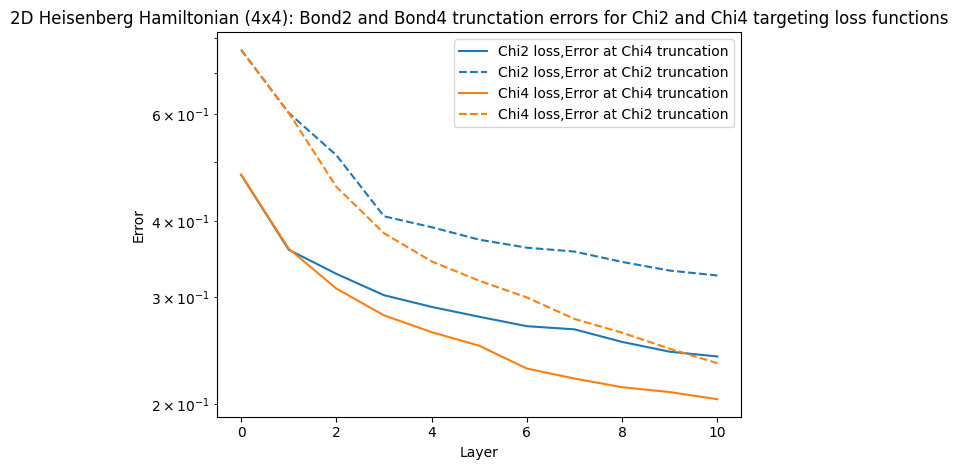

In [21]:
# example data
fid2_joshopt = [0.23596097887846954,
 0.3981301007592116,
 0.48691666760677654,
 0.5927161216930499,
 0.6091497908268707,
 0.6271816820336384,
 0.6382972723630356,
 0.6435407571775136,
 0.6572095480994304,
 0.6682704656409655,
 0.6743641874859737]
fid4_joshopt = [0.5236102978279489,
 0.6410659646756625,
 0.67231168575891,
 0.6977424696172129,
 0.7107780951783319,
 0.7213895334650986,
 0.7311443388244043,
 0.7343223838969584,
 0.7466407380243711,
 0.7558553176219212,
 0.7602072451063738]

fid2_archopt = [0.2360,0.3979, 0.5447,0.6180,0.6565,0.6808,0.7003,0.7237,0.7377,0.7531,0.7662]
fid4_archopt = [0.5236,0.6396,0.6901,0.7199,0.7371,0.7503,0.7709,0.7794,0.7865,0.7904,0.7960]

fid2_joshopt_err  = [1 - f for f in fid2_joshopt]
fid4_joshopt_err  = [1 - f for f in fid4_joshopt]
fid2_archopt_err  = [1 - f for f in fid2_archopt]
fid4_archopt_err  = [1 - f for f in fid4_archopt]


x = range(len(fid2_joshopt))  # index-based x-axis

# first pair (same colour)
plt.plot(x, fid4_joshopt_err, color="tab:blue", linestyle="-", label="Chi2 loss,Error at Chi4 truncation")
plt.plot(x, fid2_joshopt_err, color="tab:blue", linestyle="--", label="Chi2 loss,Error at Chi2 truncation")

# second pair (different colour)
plt.plot(x, fid4_archopt_err, color="tab:orange", linestyle="-", label="Chi4 loss,Error at Chi4 truncation")
plt.plot(x, fid2_archopt_err, color="tab:orange", linestyle="--", label="Chi4 loss,Error at Chi2 truncation")

plt.yscale("log")
plt.xlabel("Layer")
plt.ylabel("Error")
plt.title("2D Heisenberg Hamiltonian (4x4): Bond2 and Bond4 trunctation errors for Chi2 and Chi4 targeting loss functions")
plt.legend()
plt.tight_layout()
plt.show()


This is really strange, it looks like the Chi4 loss function is better at getting even the chi2 truncation error down, better than the loss function designed to target the chi2 loss state.

### 1D Hubbard Hamilonian

In [22]:
# --- Parameters ---
n = 16                  # number of sites
t = 0.5                 # hopping energy
V = 1.0                 # interaction energy
mu = 1.0                # chemical potential
cyclic = False           # open boundary
parallel = False         # parallel construction of H

# --- Step 1: Build the Hubbard hardcore Hamiltonian ---
H = qu.ham_hubbard_hardcore(
    n=n,
    t=t,
    V=V,
    mu=mu,
    cyclic=cyclic,
    parallel=parallel,
    sparse=True
)

# --- Step 2: Solve for the ground state ---
evals, evecs = qu.eigh(H, k=1)  # smallest eigenvalue & eigenvector
E0 = float(evals[0])
psi0 = evecs if evecs.ndim == 1 else evecs[:, 0]  # ensure 1D vector

# --- Step 3: Convert dense statevector to an MPS ---
mps_hub = qtn.MatrixProductState.from_dense(
    psi0,
    cutoff=0.0   # exact initially
)

# --- Step 4: Optionally compress the MPS ---
mps_hub.compress(max_bond=64, cutoff=1e-10)
mps_hub /= mps_hub.norm()  # normalize

#### Layer=su4, Loss=chi2

In [23]:
target_mps=mps_hub.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = partial(new_torch_schmidt_loss_fn, g=0) 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  12%|█▏        | 71/600 [00:01<00:10, 49.78it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([5.3015e-01, 4.5954e-01, 4.6565e-03, 3.9252e-03, 5.6765e-04, 4.1937e-04,
        3.6837e-04, 3.6425e-04, 3.7577e-06, 3.0825e-06, 5.0836e-07, 3.2286e-07,
        3.1512e-07, 2.8041e-07, 3.8484e-08, 3.3503e-08, 2.6413e-09, 1.6354e-09,
        1.6191e-09, 1.4349e-09, 5.7501e-10, 4.5573e-10, 2.4000e-10, 1.9638e-10,
        8.2133e-11, 5.5930e-11, 4.8897e-11, 4.8390e-11, 3.3891e-11, 2.6754e-11,
        2.1909e-11], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.4922738206675577
 bond 2 = 0.7015451627931113
 bond 4 = 0.9917149284712811
 bond 8 = 0.9999525283289846

 LAYER 0
initial loss = 0.44174280964096135
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.94806737 0.23924501 0.31922671 0.18178655 0.30794312 0.17569169
 0.31600079 0.17713311 0.32221832 0.19009238 0.35419421 0.26065835
 0.60596744 0.91090266]
New tail entropy term = 5.309127707971385
te

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.052544119125 [best: +0.052543762544] : : 877it [04:55,  2.97it/s]                       


...

+0.000665015743 [best: +0.000624947939] : : 870it [03:14,  4.48it/s]                       



 LAYER 9
initial loss = 0.0015073107613019499
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [2.92965776e-01 7.87715056e-04 4.77298960e-01 7.04763736e-01
 5.77313925e-01 9.20585548e-01 2.47885115e-01 3.78845971e-01
 3.87376943e-01 4.90453782e-01 6.33538692e-04 1.30070678e-02
 6.89212073e-01 9.04589001e-02]
New tail entropy term = 5.271589052202992
tensor([1.8563e-12, 1.2698e-07, 7.5458e-09, 1.1560e-07, 4.0224e-07, 5.1010e-07,
        3.8363e-07, 3.2171e-04, 4.9201e-04, 4.6838e-04, 1.1840e-04, 1.0493e-04,
        1.5099e-07, 1.8202e-07], dtype=torch.float64)
At init net entropy comp = 10.56120342443968 // tail loss = 0.0015073107613019499


+0.001497393597 [best: +0.001495640602] :  22%|██▏       | 179/800 [00:47<02:45,  3.75it/s]


final loss = 0.0014956406016818358
best val = 0.0014956406016818358. Final loss = 0.0014956406016818358
after updating, final loss = 0.0014956406016818358
Tail entropy (normalised) per cut: [0.27487402 0.41502942 0.37295879 0.73425744 0.8649891  0.10378702
 0.18504581 0.37777835 0.38925031 0.49044327 0.0972317  0.17144255
 0.66219205 0.52530132]
New tail entropy term = 5.664581145571585
tensor([2.0310e-12, 4.4672e-07, 7.3063e-10, 4.4974e-10, 4.6141e-08, 1.2571e-10,
        1.4637e-10, 3.2089e-04, 4.9065e-04, 4.6836e-04, 1.1483e-04, 1.0043e-04,
        2.9719e-11, 1.2346e-11], dtype=torch.float64)
After opt: net entropy comp = 10.763213049900328 // tail loss = 0.0014956406016818358
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.995353116376923
 error from singular value truncation ~ (3.4601239430331887e-06+2.775567165369296e-17j), cut from max bond 8 to 4. sv cutoff = 0.0001
 new max bond = 4
norm = (0.9999999999999983-2.775557561562896e-1

+0.999999229612 [best: +0.999999229612] :   0%|          | 3/800 [00:00<03:08,  4.23it/s]


#### Layer=su4, Loss=chi4

In [24]:
target_mps=mps_hub.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = arch_chi4_torch_schmidt_loss_fn

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 49/600 [00:00<00:09, 57.98it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([5.3015e-01, 4.5954e-01, 4.6565e-03, 3.9252e-03, 5.6765e-04, 4.1937e-04,
        3.6837e-04, 3.6425e-04, 3.7577e-06, 3.0825e-06, 5.0836e-07, 3.2286e-07,
        3.1512e-07, 2.8041e-07, 3.8484e-08, 3.3503e-08, 2.6413e-09, 1.6354e-09,
        1.6191e-09, 1.4349e-09, 5.7501e-10, 4.5573e-10, 2.4000e-10, 1.9638e-10,
        8.2133e-11, 5.5930e-11, 4.8897e-11, 4.8390e-11, 3.3891e-11, 2.6754e-11,
        2.1909e-11], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.4922738206675577
 bond 2 = 0.7015451627931113
 bond 4 = 0.9917149284712811
 bond 8 = 0.9999525283289846

 LAYER 0
initial loss = 0.4417346157436519
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.94808711 0.23925601 0.31922628 0.18178587 0.30794398 0.17569272
 0.31600146 0.17713596 0.32221791 0.19009206 0.35419418 0.26066064
 0.60596919 0.91093823]
New tail entropy term = 5.309201594942397
ten

+0.052544625853 [best: +0.052543741233] : : 1152it [06:37,  2.89it/s]                      


final loss = 0.052543741232691565
best val = 0.052543741232691565. Final loss = 0.052543741232691565
after updating, final loss = 0.052543741232691565
Tail entropy (normalised) per cut: [0.94403928 0.22435197 0.43769171 0.25230659 0.42931074 0.27944259
 0.42920235 0.31889626 0.4093219  0.38613312 0.43351454 0.55617118
 0.68657361 0.9327275 ]
New tail entropy term = 6.719683344804368
tensor([2.3439e-12, 2.3805e-03, 7.7502e-04, 5.6646e-03, 1.9613e-03, 8.1303e-03,
        3.0006e-03, 8.8639e-03, 3.5668e-03, 7.0550e-03, 3.5923e-03, 4.3447e-03,
        2.2990e-03, 9.0981e-04], dtype=torch.float64)
After opt: net entropy comp = 11.05740931873429 // tail loss = 0.052543741232691565
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.971060603413128


...

+0.000863987546 [best: +0.000863987546] : : 1275it [04:49,  4.41it/s]                      



 LAYER 9
initial loss = 0.0023869717256308487
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.00000000e+00 2.47524176e-01 2.93145505e-01 2.20464509e-01
 4.61868384e-01 4.83974191e-04 6.26529470e-04 4.77751147e-01
 3.29497390e-03 3.21399607e-01 3.81223325e-01 9.82366901e-01
 7.28814857e-01 4.73940603e-01]
New tail entropy term = 4.592904491299599
tensor([2.2549e-13, 1.9267e-09, 1.4497e-10, 8.8501e-09, 3.0678e-09, 1.1324e-04,
        1.1724e-04, 3.9047e-04, 3.8996e-04, 3.8766e-04, 5.2332e-04, 4.6396e-04,
        8.0701e-07, 3.0240e-07], dtype=torch.float64)
At init net entropy comp = 8.982831225515335 // tail loss = 0.002386971725856335


+0.002384448623 [best: +0.002384081024] :  29%|██▉       | 232/800 [01:02<02:33,  3.70it/s]


final loss = 0.002384081024246809
best val = 0.002384081024246809. Final loss = 0.002384081024246809
after updating, final loss = 0.002384081024246809
Tail entropy (normalised) per cut: [0.00000000e+00 2.57195481e-01 2.92026631e-01 3.34790833e-01
 4.40329957e-01 6.31095078e-05 9.98110112e-03 4.77192129e-01
 2.53127745e-04 3.20867226e-01 3.80563924e-01 9.82921413e-01
 3.34842519e-01 2.41627330e-01]
New tail entropy term = 4.072654780483452
tensor([2.2571e-13, 1.4823e-09, 1.4183e-10, 2.4415e-10, 2.3224e-09, 1.1323e-04,
        1.1671e-04, 3.9031e-04, 3.8967e-04, 3.8749e-04, 5.2295e-04, 4.6372e-04,
        1.1854e-10, 3.9434e-11], dtype=torch.float64)
After opt: net entropy comp = 8.982393941527109 // tail loss = 0.0023840810244725175
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.994975260973029
 error from singular value truncation ~ (1.535161643362315e-07+8.326673962967723e-17j), cut from max bond 8 to 4. sv cutoff = 0.0001
 new max bond 

+0.000863677203 [best: +0.000862549003] : : 1148it [04:19,  4.43it/s]                      


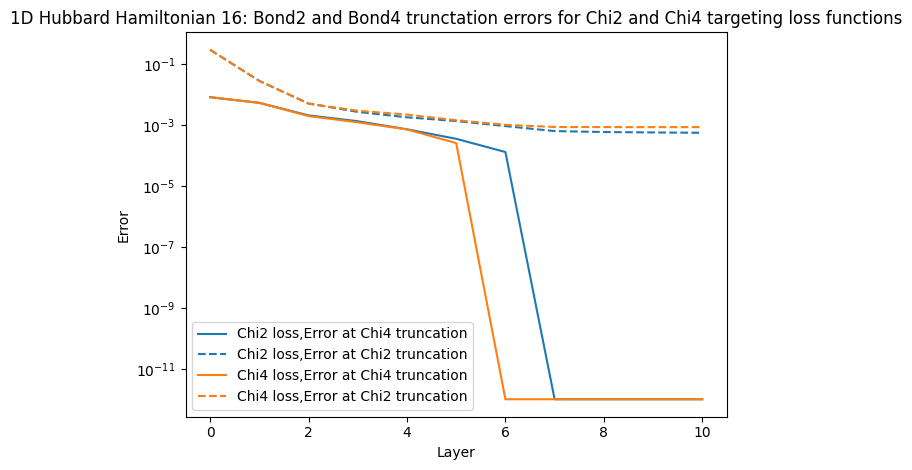

In [30]:
# example data
fid2_joshopt = [0.7015451627931113,0.9715665492521919,0.9948313733743455,0.9972717657594302,0.9981896280916837,0.998629927670859,0.9990667349756387,0.9993604334330973,0.999404150770533,0.9994234605414914,0.9994381738042878]
fid4_joshopt = [0.9917149284712811,0.9945909423716204,0.9979049338325855,0.9986530093209892,0.999268015902884,0.9996431014312167,0.9998686719295447,1.0000000000000004,0.9999999999999987,1.0000000000000009,0.9999999999999984]

fid2_archopt = [0.7015451627931113,
 0.9715648223045953,
 0.9949432542167628,
 0.9970260289484758,
 0.9977727587097758,
 0.9985445010403412,
 0.99896980335013,
 0.999128798219359,
 0.9991360557465975,
 0.9991377349418928,
 0.9991384671424525]
fid4_archopt = [0.9917149284712811,
 0.9945902749876953,
 0.9980111201238384,
 0.9987583508398478,
 0.9992749990155828,
 0.9997416606139327,
 1.0000000000000013,
 1.0000000000000018,
 0.9999999999999991,
 0.9999999999999996,
 0.9999999999999991]
def fidelity_to_error(fid, eps=1e-12):
    fid = np.asarray(fid)
    err = 1.0 - fid
    # clip negative / zero errors to numerical floor
    err = np.clip(err, eps, None)
    return err

fid2_joshopt_err  = fidelity_to_error(fid2_joshopt)
fid4_joshopt_err  = fidelity_to_error(fid4_joshopt)
fid2_archopt_err  = fidelity_to_error(fid2_archopt)
fid4_archopt_err  = fidelity_to_error(fid4_archopt)


x = range(len(fid2_joshopt))  # index-based x-axis

# first pair (same colour)
plt.plot(x, fid4_joshopt_err, color="tab:blue", linestyle="-", label="Chi2 loss,Error at Chi4 truncation")
plt.plot(x, fid2_joshopt_err, color="tab:blue", linestyle="--", label="Chi2 loss,Error at Chi2 truncation")

# second pair (different colour)
plt.plot(x, fid4_archopt_err, color="tab:orange", linestyle="-", label="Chi4 loss,Error at Chi4 truncation")
plt.plot(x, fid2_archopt_err, color="tab:orange", linestyle="--", label="Chi4 loss,Error at Chi2 truncation")

plt.yscale("log")
plt.xlabel("Layer")
plt.ylabel("Error")
plt.title("1D Hubbard Hamiltonian 16: Bond2 and Bond4 trunctation errors for Chi2 and Chi4 targeting loss functions")
plt.legend()
plt.tight_layout()
plt.show()


Hm okay. To interpret remember dotted is chi2 trucation and solid is chi 4 truncation. This really seems like the choice of wether we truncate to chi2 or chi4 is more important than the loss function used. Unlike with Heisenbeg (which Josh rekons is plagued by difficuult optimisation) we have the "correct" loss function doing its work where needed, like the chi2 loss does a better job for chi2 truncation and the chi4 does a good job for chi4 truncation.

### 1D MBL Hamiltonian

In [31]:
# --- Parameters ---
n = 16                 # number of spins
dh = 1.0               # strength of random fields
dh_dist = 'g'          # Gaussian distribution
seed = 42              # for reproducibility

# --- Step 1: Construct the MBL Hamiltonian ---
H = qu.ham_mbl(n, dh, dh_dist=dh_dist, seed=seed, sparse=True)

# --- Step 2: Solve for the ground state (smallest eigenvalue) ---
evals, evecs = qu.eigh(H, k=1)  # sparse Hermitian solver, lowest energy
E0 = float(evals[0])
psi0 = evecs if evecs.ndim == 1 else evecs[:, 0]  # ensure it's a 1D vector

# --- Step 3: Convert the dense statevector to an MPS ---
mps = qtn.MatrixProductState.from_dense(
    psi0,
    cutoff=0.0  # exact representation initially
)

# --- Optional Step 4: Compress the MPS ---
mps.compress(max_bond=64, cutoff=1e-16)
mps /= mps.norm()  # normalize


In [32]:
target_mps=mps.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = partial(new_torch_schmidt_loss_fn, g=0) 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)
print("Bond 2 fids:")
print([t.tolist() for t in bond2_fids])
print("Bond 4 fids:")
print([t.tolist() for t in bond4_fids])

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  12%|█▏        | 69/600 [00:01<00:10, 49.92it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([6.0380e-01, 3.9254e-01, 2.9178e-03, 3.7794e-04, 3.0427e-04, 3.1351e-05,
        1.5367e-05, 1.2210e-05, 8.0102e-09, 1.3996e-09, 6.4837e-10, 1.6950e-10,
        1.5042e-10, 5.9991e-11, 5.0615e-12, 2.9841e-12, 2.3147e-12, 2.2330e-12,
        2.0525e-12, 2.0336e-12, 2.0308e-12, 2.0232e-12, 2.0142e-12, 2.0123e-12,
        2.0063e-12, 2.0059e-12, 2.0047e-12, 2.0019e-12, 2.0011e-12, 2.0003e-12,
        2.0002e-12, 2.0001e-12, 2.0001e-12, 2.0001e-12, 2.0000e-12],
       dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.5186704395875796
 bond 2 = 0.9293507826214551
 bond 4 = 0.9993358903762005
 bond 8 = 0.9999994932064256

 LAYER 0
initial loss = 0.07948149185079201
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.         0.25191655 0.21697114 0.15818609 0.2396946  0.12099868
 0.2567161  0.135649   0.1735382  0.16855451 0.33155371 0.26234603
 0.42900193 0

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.003594880054 [best: +0.003594880054] : : 1284it [07:39,  2.79it/s]                      


...


 LAYER 9
initial loss = 1.4370091607762703e-06
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.         0.08030523 0.5558479  0.77137611 0.3886355  0.94459716
 0.63294549 0.22447181 0.29219556 0.75735883 0.96046451 0.74989497
 0.99963057 0.21152615]
New tail entropy term = 7.569249776212561
tensor([4.9882e-13, 6.6837e-10, 5.5280e-10, 5.4999e-09, 1.4990e-09, 1.2059e-09,
        4.5340e-08, 1.4764e-08, 4.1623e-08, 4.1493e-07, 2.0500e-07, 2.5051e-07,
        2.0494e-07, 2.5047e-07], dtype=torch.float64)
At init net entropy comp = 8.119986681196574 // tail loss = 1.4370096595994752e-06


+0.000000407791 [best: +0.000000007756] :  48%|████▊     | 385/800 [01:49<01:58,  3.51it/s]


final loss = 7.755756259442137e-09
best val = 7.755756259442137e-09. Final loss = 7.755756259442137e-09
after updating, final loss = 7.755756259442137e-09
Tail entropy (normalised) per cut: [0.         0.08311167 0.55681682 0.65106606 0.44395441 0.94129977
 0.21218864 0.6315603  0.87463977 0.93604512 0.7117793  0.81136747
 0.99611267 0.69414737]
New tail entropy term = 8.54408937975353
tensor([4.9871e-13, 5.4002e-10, 5.4414e-10, 3.9058e-09, 1.1212e-09, 8.9817e-10,
        6.4385e-11, 1.5106e-10, 5.4356e-11, 5.3605e-11, 5.8325e-11, 1.3822e-10,
        6.6551e-11, 1.5994e-10], dtype=torch.float64)
After opt: net entropy comp = 8.119675001926542 // tail loss = 7.756254971624799e-09
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9990305019874195
 error from singular value truncation ~ (3.864562780897529e-09+1.387778786144604e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (0.9999999999999991-4.163336342344341e-17j

+0.000000188506 [best: +0.000000188506] : : 1194it [05:28,  3.63it/s]                      

Bond 2 fids:
[0.9293507826214551, 0.9986743650514708, 0.9999176914036859, 1.0000000000000004, 1.0000000000000013, 0.9999999999999996, 1.0000000000000009, 0.9999999999999987, 0.9999999999999989, 1.0, 0.9999999999999991]
Bond 4 fids:
[0.9993358903762005, 0.999813226943339, 1.0000000000000004, 1.0000000000000004, 1.0000000000000013, 0.9999999999999996, 1.0000000000000009, 0.9999999999999987, 0.9999999999999989, 1.0, 0.9999999999999991]


In [33]:
target_mps=mps.copy()
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = arch_chi4_torch_schmidt_loss_fn 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)
print("Bond 2 fids:")
print([t.tolist() for t in bond2_fids])
print("Bond 4 fids:")
print([t.tolist() for t in bond4_fids])

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   7%|▋         | 44/600 [00:00<00:12, 45.99it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([6.0380e-01, 3.9254e-01, 2.9178e-03, 3.7794e-04, 3.0427e-04, 3.1351e-05,
        1.5367e-05, 1.2210e-05, 8.0102e-09, 1.3996e-09, 6.4837e-10, 1.6950e-10,
        1.5042e-10, 5.9991e-11, 5.0615e-12, 2.9841e-12, 2.3147e-12, 2.2330e-12,
        2.0525e-12, 2.0336e-12, 2.0308e-12, 2.0232e-12, 2.0142e-12, 2.0123e-12,
        2.0063e-12, 2.0059e-12, 2.0047e-12, 2.0019e-12, 2.0011e-12, 2.0003e-12,
        2.0002e-12, 2.0001e-12, 2.0001e-12, 2.0001e-12, 2.0000e-12],
       dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.5186704395875796
 bond 2 = 0.9293507826214551
 bond 4 = 0.9993358903762005
 bond 8 = 0.9999994932064256

 LAYER 0
initial loss = 0.07948208919161814
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.         0.25189673 0.21697137 0.15821259 0.23970979 0.1210144
 0.25673394 0.13564942 0.17354041 0.16855451 0.33154672 0.26234775
 0.42899461 0.

+0.003561154738 [best: +0.003561154738] : : 1274it [08:29,  2.50it/s]                      


final loss = 0.0038196577328170056
best val = 0.003561154738480843. Final loss = 0.0038196577328170056
after updating, final loss = 0.003561154738480843
Tail entropy (normalised) per cut: [0.         0.25606173 0.27819521 0.29321597 0.32238736 0.18872349
 0.31612102 0.20790963 0.36769662 0.3234629  0.40437903 0.5287522
 0.70776594 0.3891289 ]
New tail entropy term = 4.58380001375422
tensor([7.2997e-13, 1.5940e-06, 2.0156e-06, 4.6953e-06, 3.8681e-06, 7.1405e-05,
        5.3494e-05, 5.0940e-04, 5.4363e-04, 1.0319e-03, 6.7489e-04, 4.0001e-04,
        2.0570e-04, 5.8600e-05], dtype=torch.float64)
After opt: net entropy comp = 11.741469255770893 // tail loss = 0.0035611547392108145
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9982577291067604


...


 LAYER 9
initial loss = 2.154258112896379e-06
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.         0.60017594 0.48680071 0.88000506 0.94196962 0.9855256
 0.03207341 0.53128394 0.793577   0.98695219 0.9724673  0.99213951
 0.99889707 0.44980356]
New tail entropy term = 9.651670910494868
tensor([2.2637e-13, 9.3868e-08, 7.8877e-09, 8.5984e-08, 3.5951e-08, 9.1292e-09,
        6.1875e-07, 2.1766e-08, 2.2721e-07, 5.5929e-08, 2.3965e-07, 4.7426e-07,
        2.3943e-07, 4.4428e-08], dtype=torch.float64)
At init net entropy comp = 10.811702132434798 // tail loss = 2.1542583392708536e-06


+0.000000264362 [best: +0.000000012958] :  20%|██        | 161/800 [00:45<03:01,  3.51it/s]


final loss = 1.2957704575988771e-08
best val = 1.2957704575988771e-08. Final loss = 1.2957704575988771e-08
after updating, final loss = 1.2957704575988771e-08
Tail entropy (normalised) per cut: [0.         0.12730042 0.51731896 0.77990541 0.93246981 0.96371857
 0.34214329 0.98886687 0.65130832 0.81676405 0.68968005 0.89542917
 0.97413775 0.07328828]
New tail entropy term = 8.752330951544133
tensor([2.2626e-13, 7.0358e-10, 2.7643e-09, 2.0114e-10, 2.2032e-10, 1.4359e-09,
        1.2277e-09, 5.0057e-10, 9.7839e-10, 1.6517e-10, 1.6119e-10, 1.2873e-10,
        8.4840e-10, 3.6224e-09], dtype=torch.float64)
After opt: net entropy comp = 10.811681909891224 // tail loss = 1.295793083944119e-08
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9992242377459185
 error from singular value truncation ~ (6.463311774673741e-09+2.7755575795021855e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (1+0j)
2. Central schmidt coefficie

+0.000000149695 [best: +0.000000106313] :  80%|████████  | 644/800 [02:58<00:43,  3.61it/s]

Bond 2 fids:
[0.9293507826214551, 0.9986743023852018, 0.9999505193869116, 1.0000000000000018, 1.0000000000000009, 0.9999999999999984, 0.9999999999999989, 1.0000000000000022, 0.9999999999999996, 0.9999999999999998, 0.9999999999999998]
Bond 4 fids:
[0.9993358903762005, 0.9998185611930036, 1.0000000000000009, 1.0000000000000018, 1.0000000000000009, 0.9999999999999984, 0.9999999999999989, 1.0000000000000022, 0.9999999999999996, 0.9999999999999998, 0.9999999999999998]


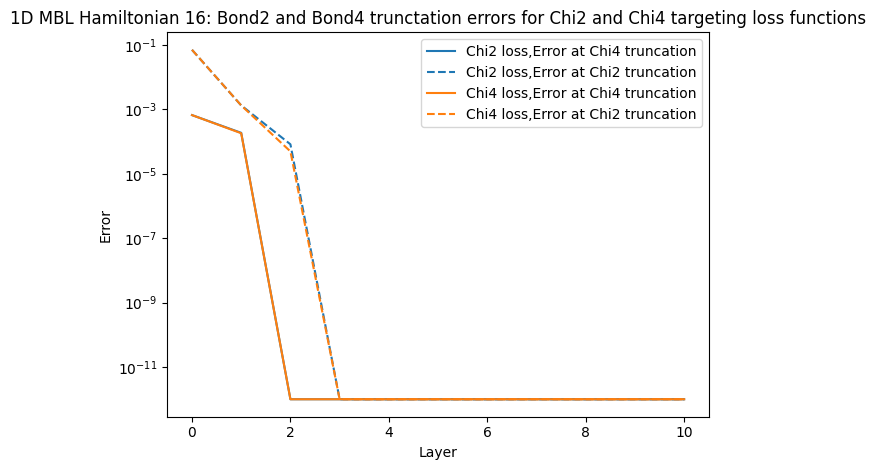

In [34]:
# example data
fid2_joshopt = [0.9293507826214551, 0.9986743650514708, 0.9999176914036859, 1.0000000000000004, 1.0000000000000013, 0.9999999999999996, 1.0000000000000009, 0.9999999999999987, 0.9999999999999989, 1.0, 0.9999999999999991]
fid4_joshopt =[0.9993358903762005, 0.999813226943339, 1.0000000000000004, 1.0000000000000004, 1.0000000000000013, 0.9999999999999996, 1.0000000000000009, 0.9999999999999987, 0.9999999999999989, 1.0, 0.9999999999999991]

fid2_archopt = [0.9293507826214551, 0.9986743023852018, 0.9999505193869116, 1.0000000000000018, 1.0000000000000009, 0.9999999999999984, 0.9999999999999989, 1.0000000000000022, 0.9999999999999996, 0.9999999999999998, 0.9999999999999998]
fid4_archopt = [0.9993358903762005, 0.9998185611930036, 1.0000000000000009, 1.0000000000000018, 1.0000000000000009, 0.9999999999999984, 0.9999999999999989, 1.0000000000000022, 0.9999999999999996, 0.9999999999999998, 0.9999999999999998]
def fidelity_to_error(fid, eps=1e-12):
    fid = np.asarray(fid)
    err = 1.0 - fid
    # clip negative / zero errors to numerical floor
    err = np.clip(err, eps, None)
    return err

fid2_joshopt_err  = fidelity_to_error(fid2_joshopt)
fid4_joshopt_err  = fidelity_to_error(fid4_joshopt)
fid2_archopt_err  = fidelity_to_error(fid2_archopt)
fid4_archopt_err  = fidelity_to_error(fid4_archopt)


x = range(len(fid2_joshopt))  # index-based x-axis

# first pair (same colour)
plt.plot(x, fid4_joshopt_err, color="tab:blue", linestyle="-", label="Chi2 loss,Error at Chi4 truncation")
plt.plot(x, fid2_joshopt_err, color="tab:blue", linestyle="--", label="Chi2 loss,Error at Chi2 truncation")

# second pair (different colour)
plt.plot(x, fid4_archopt_err, color="tab:orange", linestyle="-", label="Chi4 loss,Error at Chi4 truncation")
plt.plot(x, fid2_archopt_err, color="tab:orange", linestyle="--", label="Chi4 loss,Error at Chi2 truncation")

plt.yscale("log")
plt.xlabel("Layer")
plt.ylabel("Error")
plt.title("1D MBL Hamiltonian 16: Bond2 and Bond4 trunctation errors for Chi2 and Chi4 targeting loss functions")
plt.legend()
plt.tight_layout()
plt.show()


hmm not sure why this is cutoff like this i think the numerical error must be different for josh and i's simulation.

### Simple Wrist Image

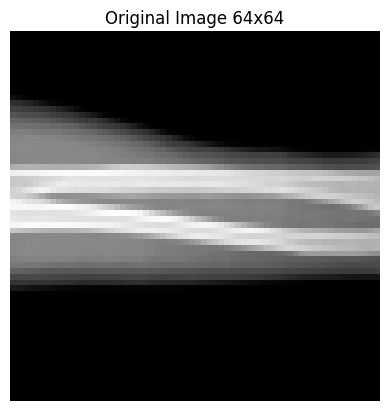

In [41]:
import matplotlib.image as mpimg
simplewristimg = mpimg.imread("simple_wrist.png")[:, :, 0]
simplewristimg_condense = resize(simplewristimg, (64,64), anti_aliasing=True)
plt.imshow(simplewristimg_condense, cmap='gray')
plt.title("Original Image 64x64")
plt.axis('off')
plt.show()

In [47]:
target_mps=image_to_mps(simplewristimg_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = partial(new_torch_schmidt_loss_fn, g=0) 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)
print("Bond 2 fids:")
print([t.tolist() for t in bond2_fids])
print("Bond 4 fids:")
print([t.tolist() for t in bond4_fids])

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  12%|█▏        | 71/600 [00:01<00:11, 46.53it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([9.8622e-01, 1.1607e-02, 1.7871e-03, 2.9919e-04, 5.3453e-05, 1.4200e-05,
        7.4438e-06, 2.4534e-06, 2.0116e-06, 1.0201e-06, 7.5014e-07, 6.3680e-07,
        2.3654e-07, 1.2256e-07, 9.9165e-08, 5.5465e-08], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.9727765378566144
 bond 2 = 0.9666237522923455
 bond 4 = 0.996437884376799
 bond 8 = 0.9999638200891148

 LAYER 0
initial loss = 0.05677692850896088
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [6.06195427e-01 3.01386648e-05 3.16217932e-01 2.72309221e-01
 2.42130595e-01 2.28053520e-01 2.53365086e-01 5.07798660e-01]
New tail entropy term = 2.4261005793826214
tensor([2.2862e-12, 4.2175e-03, 1.9784e-02, 2.2200e-02, 8.1089e-03, 2.1690e-03,
        2.7109e-04, 2.5877e-05], dtype=torch.float64)
At init net entropy comp = 3.1188162035937865 // tail loss = 0.05677692850896088


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.020601881431 [best: +0.020601881431] : : 1272it [02:47,  7.60it/s]                      


...


 LAYER 9
initial loss = 2.567972731126744e-07
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.         0.07425122 0.11851988 0.47162949 0.03930399 0.41719675
 0.02190363 0.02213825]
New tail entropy term = 1.1649432047233867
tensor([6.4193e-13, 6.4808e-08, 3.0370e-08, 9.4120e-08, 6.8213e-09, 1.7321e-09,
        5.6702e-08, 2.2450e-09], dtype=torch.float64)
At init net entropy comp = 1.6449932219133265 // tail loss = 2.5679791504362726e-07


+0.000000168703 [best: +0.000000004698] :  19%|█▉        | 155/800 [00:19<01:21,  7.94it/s]


final loss = 4.698127331614899e-09
best val = 4.698127331614899e-09. Final loss = 4.698127331614899e-09
after updating, final loss = 4.698127331614899e-09
Tail entropy (normalised) per cut: [0.         0.02675784 0.43030747 0.31137254 0.44837186 0.33001778
 0.75317704 0.10130024]
New tail entropy term = 2.401304778293999
tensor([6.4193e-13, 1.9373e-10, 1.3792e-09, 1.0633e-09, 4.9994e-10, 2.8890e-10,
        1.2752e-10, 1.1455e-09], dtype=torch.float64)
After opt: net entropy comp = 1.6446274453977727 // tail loss = 4.698769262567737e-09
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9982482916527375
 error from singular value truncation ~ (2.3434432172564357e-09-2.397149464417745e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (1.0000000000000013+3.737758323392682e-17j)
2. Central schmidt coefficients = tensor([0.9832, 0.0168], dtype=torch.float64)
 bond 2 = 0.9999999999999993
 bond 4 = 0.9999999999999993
 bon

+0.000000049658 [best: +0.000000038847] : : 812it [01:50,  7.32it/s]                       


Bond 2 fids:
[0.9666237522923455, 0.9907958605523974, 0.9954207117478195, 0.9979843475549136, 0.9987680314448318, 0.999343914806193, 0.9997568090480093, 0.9999278667327418, 1.0000000000000018, 1.0000000000000004, 0.9999999999999993]
Bond 4 fids:
[0.996437884376799, 0.9975685812002133, 0.9986800833759094, 0.9990269918803689, 0.9993513134598341, 0.9997573281848166, 0.9999999999999987, 0.9999999999999987, 1.0000000000000018, 1.0000000000000004, 0.9999999999999993]


In [48]:
target_mps=image_to_mps(simplewristimg_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = arch_chi4_torch_schmidt_loss_fn

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)
print("Bond 2 fids:")
print([t.tolist() for t in bond2_fids])
print("Bond 4 fids:")
print([t.tolist() for t in bond4_fids])

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 50/600 [00:00<00:10, 50.53it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([9.8622e-01, 1.1607e-02, 1.7871e-03, 2.9919e-04, 5.3453e-05, 1.4200e-05,
        7.4438e-06, 2.4534e-06, 2.0116e-06, 1.0201e-06, 7.5014e-07, 6.3680e-07,
        2.3654e-07, 1.2256e-07, 9.9165e-08, 5.5465e-08], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.9727765378566144
 bond 2 = 0.9666237522923455
 bond 4 = 0.996437884376799
 bond 8 = 0.9999638200891148

 LAYER 0
initial loss = 0.05676716765497347
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [6.06197161e-01 1.28816474e-06 3.16276304e-01 2.72268882e-01
 2.42122034e-01 2.27993632e-01 2.53740463e-01 5.03943101e-01]
New tail entropy term = 2.422542866097074
tensor([2.2862e-12, 4.2185e-03, 1.9772e-02, 2.2203e-02, 8.1084e-03, 2.1689e-03,
        2.7119e-04, 2.5848e-05], dtype=torch.float64)
At init net entropy comp = 3.118770740779799 // tail loss = 0.05676716765497347


+0.021458708057 [best: +0.021458708057] : : 1263it [02:57,  7.13it/s]                      


final loss = 0.024538318486042265
best val = 0.02145870805658634. Final loss = 0.024538318486042265
after updating, final loss = 0.02145870805658634
Tail entropy (normalised) per cut: [0.75090619 0.00626509 0.37703508 0.44837865 0.45567089 0.3500949
 0.3039082  0.50156771]
New tail entropy term = 3.193826715217233
tensor([3.9225e-12, 3.6241e-03, 7.2622e-03, 5.2687e-03, 3.1860e-03, 1.8258e-03,
        2.6624e-04, 2.5678e-05], dtype=torch.float64)
After opt: net entropy comp = 1.2826683595118094 // tail loss = 0.02145870805658634
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9889900727033931
 error from singular value truncation ~ (0.0001239973832634078+8.280879745948809e-18j), cut from max bond 32 to 8. sv cutoff = 0.0001
 new max bond = 8
norm = (1-4.012114491479843e-17j)


...


 LAYER 9
initial loss = 1.7477978867530553e-06
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.         0.09670797 0.34315629 0.29845172 0.0579901  0.03888267
 0.00375812 0.24806702]
New tail entropy term = 1.087013885263988
tensor([8.9728e-13, 7.5841e-08, 2.0132e-09, 2.5726e-10, 1.5965e-07, 1.3418e-08,
        1.4898e-06, 6.8423e-09], dtype=torch.float64)
At init net entropy comp = 2.633493969274485 // tail loss = 1.7477987840353038e-06


+0.000000984896 [best: +0.000000007229] :  26%|██▌       | 209/800 [00:26<01:14,  7.95it/s]


final loss = 7.2285030183749654e-09
best val = 7.2285030183749654e-09. Final loss = 7.2285030183749654e-09
after updating, final loss = 7.2285030183749654e-09
Tail entropy (normalised) per cut: [0.         0.23406498 0.80616205 0.29261858 0.04384224 0.8002071
 0.03839971 0.26156885]
New tail entropy term = 2.4768635027273076
tensor([8.9717e-13, 8.9537e-10, 6.8662e-11, 2.3666e-10, 1.4947e-09, 3.1004e-10,
        3.2707e-10, 3.8960e-09], dtype=torch.float64)
After opt: net entropy comp = 2.6333417195673525 // tail loss = 7.229400189601165e-09
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9981972583557852
 error from singular value truncation ~ (3.608210952243951e-09-1.852457619189913e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (1.0000000000000016-1.5797021002155187e-18j)
2. Central schmidt coefficients = tensor([0.9967, 0.0033], dtype=torch.float64)
 bond 2 = 1.0
 bond 4 = 1.0
 bond 6 = 1.0
optimising for c

+0.000000097387 [best: +0.000000046706] : : 964it [02:09,  7.46it/s]                       

Bond 2 fids:
[0.9666237522923455, 0.9892286951301748, 0.9954660636994257, 0.9977191397710286, 0.9983895497316206, 0.9991051464378163, 0.9995042868514047, 0.9997472369290434, 1.0000000000000013, 0.9999999999999998, 1.0]
Bond 4 fids:
[0.996437884376799, 0.9969165793149135, 0.9985494390023958, 0.998949953358068, 0.9992895547901315, 0.999588756071749, 0.9998341847716367, 0.9999999999999993, 1.0000000000000013, 0.9999999999999998, 1.0]


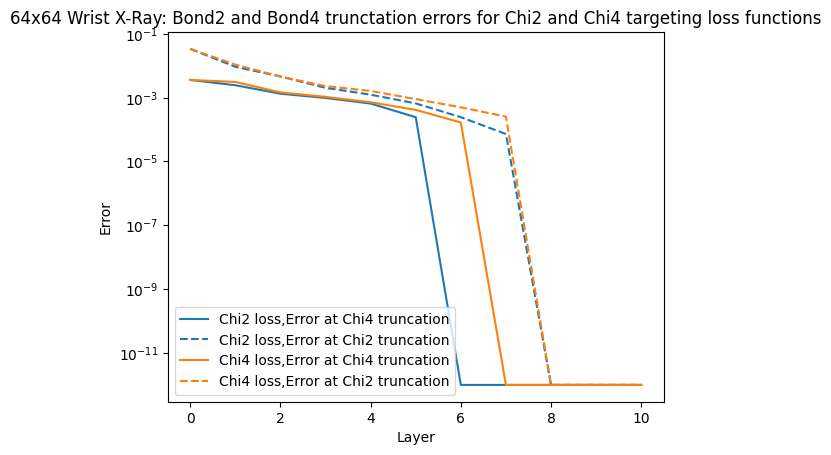

In [49]:
# example data
fid2_joshopt = [0.9666237522923455, 0.9907958605523974, 0.9954207117478195, 0.9979843475549136, 0.9987680314448318, 0.999343914806193, 0.9997568090480093, 0.9999278667327418, 1.0000000000000018, 1.0000000000000004, 0.9999999999999993]
fid4_joshopt =[0.996437884376799, 0.9975685812002133, 0.9986800833759094, 0.9990269918803689, 0.9993513134598341, 0.9997573281848166, 0.9999999999999987, 0.9999999999999987, 1.0000000000000018, 1.0000000000000004, 0.9999999999999993]

fid2_archopt = [0.9666237522923455, 0.9892286951301748, 0.9954660636994257, 0.9977191397710286, 0.9983895497316206, 0.9991051464378163, 0.9995042868514047, 0.9997472369290434, 1.0000000000000013, 0.9999999999999998, 1.0]
fid4_archopt =[0.996437884376799, 0.9969165793149135, 0.9985494390023958, 0.998949953358068, 0.9992895547901315, 0.999588756071749, 0.9998341847716367, 0.9999999999999993, 1.0000000000000013, 0.9999999999999998, 1.0]
def fidelity_to_error(fid, eps=1e-12):
    fid = np.asarray(fid)
    err = 1.0 - fid
    # clip negative / zero errors to numerical floor
    err = np.clip(err, eps, None)
    return err

fid2_joshopt_err  = fidelity_to_error(fid2_joshopt)
fid4_joshopt_err  = fidelity_to_error(fid4_joshopt)
fid2_archopt_err  = fidelity_to_error(fid2_archopt)
fid4_archopt_err  = fidelity_to_error(fid4_archopt)


x = range(len(fid2_joshopt))  # index-based x-axis

# first pair (same colour)
plt.plot(x, fid4_joshopt_err, color="tab:blue", linestyle="-", label="Chi2 loss,Error at Chi4 truncation")
plt.plot(x, fid2_joshopt_err, color="tab:blue", linestyle="--", label="Chi2 loss,Error at Chi2 truncation")

# second pair (different colour)
plt.plot(x, fid4_archopt_err, color="tab:orange", linestyle="-", label="Chi4 loss,Error at Chi4 truncation")
plt.plot(x, fid2_archopt_err, color="tab:orange", linestyle="--", label="Chi4 loss,Error at Chi2 truncation")

plt.yscale("log")
plt.xlabel("Layer")
plt.ylabel("Error")
plt.title("64x64 Wrist X-Ray: Bond2 and Bond4 trunctation errors for Chi2 and Chi4 targeting loss functions")
plt.legend()

bruh what this makes no sense. the blue (chi2 loss) is now outperforming in both trunctations, this is strange and maybe with other results kind of suggests that the loss function itself does not matter as much?

### Super Simple Wrist Image

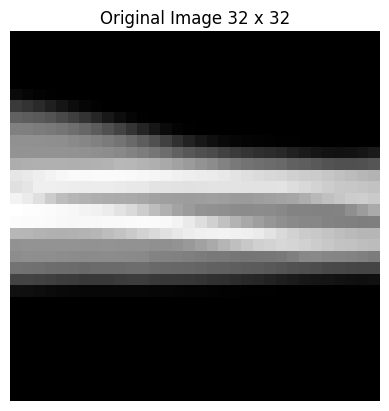

In [42]:
import matplotlib.image as mpimg
simplewristimg = mpimg.imread("simple_wrist.png")[:, :, 0]
simplewristimg_condense = resize(simplewristimg, (32,32), anti_aliasing=True)
plt.imshow(simplewristimg_condense, cmap='gray')
plt.title("Original Image 32 x 32")
plt.axis('off')
plt.show()

In [38]:
target_mps=image_to_mps(simplewristimg_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = partial(new_torch_schmidt_loss_fn, g=0) 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)
print("Bond 2 fids:")
print([t.tolist() for t in bond2_fids])
print("Bond 4 fids:")
print([t.tolist() for t in bond4_fids])

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  12%|█▏        | 71/600 [00:01<00:10, 50.75it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([9.8622e-01, 1.1607e-02, 1.7871e-03, 2.9919e-04, 5.3453e-05, 1.4200e-05,
        7.4438e-06, 2.4534e-06, 2.0116e-06, 1.0201e-06, 7.5014e-07, 6.3680e-07,
        2.3654e-07, 1.2256e-07, 9.9165e-08, 5.5465e-08], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.9727765378566144
 bond 2 = 0.9666237522923455
 bond 4 = 0.996437884376799
 bond 8 = 0.9999638200891148

 LAYER 0
initial loss = 0.05677524353599317
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [6.06198883e-01 6.14630484e-05 3.16222551e-01 2.72296783e-01
 2.42103529e-01 2.28072552e-01 2.53034438e-01 5.07565605e-01]
New tail entropy term = 2.4255558053136257
tensor([2.2862e-12, 4.2182e-03, 1.9782e-02, 2.2202e-02, 8.1076e-03, 2.1690e-03,
        2.7104e-04, 2.5884e-05], dtype=torch.float64)
At init net entropy comp = 3.1187856182987073 // tail loss = 0.05677524353599317


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.020857050037 [best: +0.020857050037] : : 1267it [02:50,  7.41it/s]                      


...


 LAYER 9
initial loss = 1.0462743477157588e-06
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.76432436 0.08814529 0.45279199 0.00125649 0.54711316 0.03870087
 0.02292938 0.06271396]
New tail entropy term = 1.9779755119740003
tensor([2.3905e-12, 1.2429e-08, 3.9418e-07, 2.0328e-08, 1.4321e-09, 6.1070e-07,
        4.4057e-09, 2.7933e-09], dtype=torch.float64)
At init net entropy comp = 1.8254854919667496 // tail loss = 1.0462743477157588e-06


+0.000000536445 [best: +0.000000008749] :  26%|██▌       | 204/800 [00:25<01:15,  7.87it/s]


final loss = 8.748934798852304e-09
best val = 8.748934798852304e-09. Final loss = 8.748934798852304e-09
after updating, final loss = 8.748934798852304e-09
Tail entropy (normalised) per cut: [0.76434135 0.12253719 0.69391907 0.81328098 0.53474314 0.11274672
 0.05789124 0.63264915]
New tail entropy term = 3.73210882850213
tensor([2.3905e-12, 3.7829e-10, 9.2622e-10, 5.4339e-09, 1.1015e-09, 5.4974e-10,
        2.9062e-10, 6.6270e-11], dtype=torch.float64)
After opt: net entropy comp = 1.8258622877899207 // tail loss = 8.748934798852304e-09
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.998194274082217
 error from singular value truncation ~ (4.367555872519802e-09+1.3149137160545372e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (0.9999999999999993-3.45747505983471e-17j)
2. Central schmidt coefficients = tensor([0.9987, 0.0013], dtype=torch.float64)
 bond 2 = 0.9999999999999984
 bond 4 = 0.9999999999999984
 bond 6

+0.000000196975 [best: +0.000000190605] : : 1037it [02:21,  7.32it/s]                      

Bond 2 fids:
[0.9666237522923455, 0.9905315617412803, 0.9958866513500242, 0.9980074324208555, 0.9986431606610019, 0.9993189760101919, 0.9997045943065377, 0.9999175684098034, 0.9999999999999993, 0.999999999999998, 0.9999999999999984]
Bond 4 fids:
[0.996437884376799, 0.9977128287876105, 0.998276710752761, 0.9988882268326204, 0.9994256422053275, 0.9997893888869576, 0.9999999999999996, 1.0000000000000018, 0.9999999999999993, 0.999999999999998, 0.9999999999999984]


In [39]:
target_mps=image_to_mps(simplewristimg_condense)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) 
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L)

#CHOOSE LOSS FUNCTION HERE
loss = arch_chi4_torch_schmidt_loss_fn 

mps_states,param_set,bond2_fids,bond4_fids,approx_states,schmidts_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)
print("Bond 2 fids:")
print([t.tolist() for t in bond2_fids])
print("Bond 4 fids:")
print([t.tolist() for t in bond4_fids])

Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   7%|▋         | 44/600 [00:00<00:10, 54.32it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([9.8622e-01, 1.1607e-02, 1.7871e-03, 2.9919e-04, 5.3453e-05, 1.4200e-05,
        7.4438e-06, 2.4534e-06, 2.0116e-06, 1.0201e-06, 7.5014e-07, 6.3680e-07,
        2.3654e-07, 1.2256e-07, 9.9165e-08, 5.5465e-08], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.9727765378566144
 bond 2 = 0.9666237522923455
 bond 4 = 0.996437884376799
 bond 8 = 0.9999638200891148

 LAYER 0
initial loss = 0.056768219391708064
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [6.06208123e-01 3.62611980e-05 3.16226586e-01 2.72341460e-01
 2.42108854e-01 2.27893781e-01 2.53517243e-01 5.10168993e-01]
New tail entropy term = 2.428501302304439
tensor([2.2864e-12, 4.2166e-03, 1.9781e-02, 2.2199e-02, 8.1064e-03, 2.1683e-03,
        2.7114e-04, 2.5938e-05], dtype=torch.float64)
At init net entropy comp = 3.1187876986442555 // tail loss = 0.056768219391708064


+0.020952423861 [best: +0.019445415987] : : 1193it [02:45,  7.20it/s]                      


final loss = 0.020952423861383296
best val = 0.019445415986914294. Final loss = 0.020952423861383296
after updating, final loss = 0.019445415986914294
Tail entropy (normalised) per cut: [0.75872367 0.05805147 0.40486433 0.49157035 0.44984942 0.32105214
 0.25671183 0.49496913]
New tail entropy term = 3.2357923423774286
tensor([3.7622e-12, 3.5115e-03, 5.1474e-03, 5.0618e-03, 3.5107e-03, 1.9188e-03,
        2.6961e-04, 2.5657e-05], dtype=torch.float64)
After opt: net entropy comp = 1.34499076505519 // tail loss = 0.019445415986914294
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9920957819039296
 error from singular value truncation ~ (0.00017191899748225659+3.761806531039613e-17j), cut from max bond 32 to 9. sv cutoff = 0.0001


...


 LAYER 9
initial loss = 5.773216412707782e-07
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.92123398 0.62089655 0.28346246 0.16819877 0.38078431 0.51586481
 0.02803818 0.02357476]
New tail entropy term = 2.942053826644403
tensor([2.2543e-12, 9.2405e-08, 1.6361e-07, 5.7716e-08, 5.3641e-08, 8.5480e-09,
        2.7802e-08, 1.7360e-07], dtype=torch.float64)
At init net entropy comp = 2.169205899162148 // tail loss = 5.773216412707782e-07


+0.000000429474 [best: +0.000000015987] :  44%|████▍     | 351/800 [00:44<00:57,  7.86it/s]


final loss = 1.598683629921993e-08
best val = 1.598683629921993e-08. Final loss = 1.598683629921993e-08
after updating, final loss = 1.598683629921993e-08
Tail entropy (normalised) per cut: [0.92125431 0.37644859 0.53372541 0.69271408 0.22840478 0.53334054
 0.04442994 0.05097449]
New tail entropy term = 3.381292137555894
tensor([2.2544e-12, 1.0173e-09, 2.3039e-10, 1.2839e-09, 2.4623e-09, 6.4109e-09,
        4.3574e-09, 2.2239e-10], dtype=torch.float64)
After opt: net entropy comp = 2.1684499086635114 // tail loss = 1.598683629921993e-08
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9979617866302574
 error from singular value truncation ~ (7.986244665580955e-09-1.6379525313391736e-17j), cut from max bond 4 to 2. sv cutoff = 0.0001
 new max bond = 2
norm = (0.9999999999999998+1.6814765778168196e-17j)
2. Central schmidt coefficients = tensor([0.9151, 0.0849], dtype=torch.float64)
 bond 2 = 0.9999999999999993
 bond 4 = 0.9999999999999993
 bo

+0.000000295508 [best: +0.000000295508] : : 1066it [02:25,  7.32it/s]                      

Bond 2 fids:
[0.9666237522923455, 0.9924296569497325, 0.9957472271299772, 0.9973640531414434, 0.9985965707998229, 0.999274999293188, 0.9997800199567879, 0.99995647845049, 1.0, 0.9999999999999996, 0.9999999999999993]
Bond 4 fids:
[0.996437884376799, 0.9976791911265982, 0.9981656573110255, 0.9988964488358542, 0.9993768647375381, 0.9997364663402903, 1.0, 1.0000000000000022, 1.0, 0.9999999999999996, 0.9999999999999993]


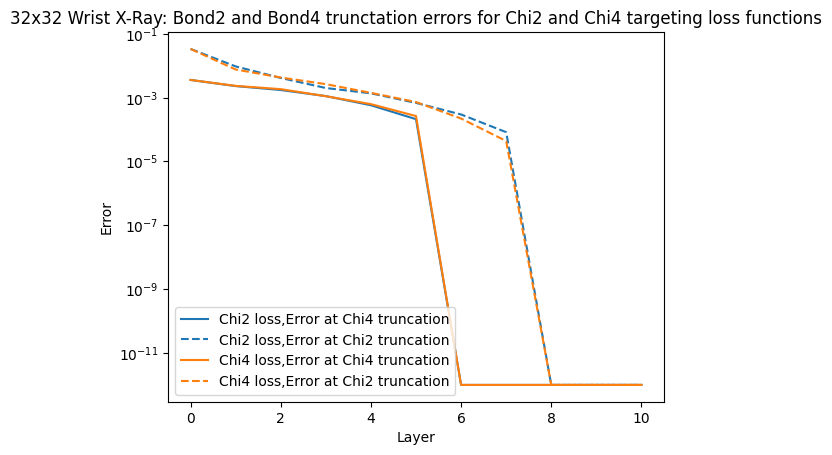

In [46]:
# example data
fid2_joshopt = [0.9666237522923455, 0.9905315617412803, 0.9958866513500242, 0.9980074324208555, 0.9986431606610019, 0.9993189760101919, 0.9997045943065377, 0.9999175684098034, 0.9999999999999993, 0.999999999999998, 0.9999999999999984]
fid4_joshopt = [0.996437884376799, 0.9977128287876105, 0.998276710752761, 0.9988882268326204, 0.9994256422053275, 0.9997893888869576, 0.9999999999999996, 1.0000000000000018, 0.9999999999999993, 0.999999999999998, 0.9999999999999984]

fid2_archopt = [0.9666237522923455, 0.9924296569497325, 0.9957472271299772, 0.9973640531414434, 0.9985965707998229, 0.999274999293188, 0.9997800199567879, 0.99995647845049, 1.0, 0.9999999999999996, 0.9999999999999993]
fid4_archopt = [0.996437884376799, 0.9976791911265982, 0.9981656573110255, 0.9988964488358542, 0.9993768647375381, 0.9997364663402903, 1.0, 1.0000000000000022, 1.0, 0.9999999999999996, 0.9999999999999993]
def fidelity_to_error(fid, eps=1e-12):
    fid = np.asarray(fid)
    err = 1.0 - fid
    # clip negative / zero errors to numerical floor
    err = np.clip(err, eps, None)
    return err

fid2_joshopt_err  = fidelity_to_error(fid2_joshopt)
fid4_joshopt_err  = fidelity_to_error(fid4_joshopt)
fid2_archopt_err  = fidelity_to_error(fid2_archopt)
fid4_archopt_err  = fidelity_to_error(fid4_archopt)


x = range(len(fid2_joshopt))  # index-based x-axis

# first pair (same colour)
plt.plot(x, fid4_joshopt_err, color="tab:blue", linestyle="-", label="Chi2 loss,Error at Chi4 truncation")
plt.plot(x, fid2_joshopt_err, color="tab:blue", linestyle="--", label="Chi2 loss,Error at Chi2 truncation")

# second pair (different colour)
plt.plot(x, fid4_archopt_err, color="tab:orange", linestyle="-", label="Chi4 loss,Error at Chi4 truncation")
plt.plot(x, fid2_archopt_err, color="tab:orange", linestyle="--", label="Chi4 loss,Error at Chi2 truncation")

plt.yscale("log")
plt.xlabel("Layer")
plt.ylabel("Error")
plt.title("32x32 Wrist X-Ray: Bond2 and Bond4 trunctation errors for Chi2 and Chi4 targeting loss functions")
plt.legend()

note that this sudden drop we see is more of an artifact of log plot than anything physical, just change graph to see.

## General Testing of different functionalities

### Function Changes for SU8 Layers

#### Builing SU8 gates

(<Figure size 2166.67x50 with 1 Axes>, <Axes: >)

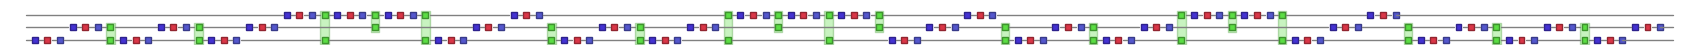

In [10]:
eps=10**(-2)

#DIY SU8 as no inbuilt SU8
qc = qtn.Circuit(3)
params=(eps*np.random.standard_normal(size=(111))).tolist()
arch_apply_su8(qc, 0, params)
qc.draw()


In [9]:
def arch_optimise_su8_gate_to_identity(eps: float = 1e-2):
    
    #DIY SU8 as no inbuilt SU8
    qc = qtn.Circuit(3)
    params=eps*np.random.standard_normal(size=(111))
    arch_apply_su8(qc,0,params)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(np.eye(8).reshape(2,2,2,2,2,2),inds=('k0','k1','k2','b0','b1','b2')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['R'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()
    #Need to take out the params I want
    ordered_params = []
    for k in sorted(params):
        v = params[k]
        # keep only scalar parameters (SU2 angles)
        if isinstance(v, np.ndarray) and v.shape == (1,):
            ordered_params.append(v.item())

    ordered_params = np.array(ordered_params)
    return ordered_params
'''Old su8 guess
def arch_apply_su8(qc: qtn.Circuit, idx, params):
    """
    This Will apply an su8 gate with the 7 layer of rotation + entangle to simulate an su8 gate.
    It will take a quantum circuit, the index that the gate is to be applied to (if you give it 0 it will be on 0,1,2), the parameters of all the rotaions as a pthyon list.
    """
    for j in range(7):
        for i in range(3):
            qc.apply_gate("rx",params[9*j+3*i],i+idx,tags=["RX","R"],parametrize=True)
            qc.apply_gate("ry",params[9*j+3*i+1],i+idx,tags=["RY","R"],parametrize=True)
            qc.apply_gate("rz",params[9*j+3*i+2],i+idx,tags=["RZ","R"],parametrize=True)
        qc.apply_gate("cnot",idx,1+idx,tags=["CNOT"])
        qc.apply_gate("cnot",1+idx,2+idx,tags=["CNOT"])
'''
def arch_apply_su8(qc: qtn.Circuit, idx, params):
    """
    This Will apply an su8 gate with the 7construction given in beyond quantum shannon.
    edit params with whatever eps you want before putting into this
    It will take a quantum circuit, the index that the gate is to be applied to (if you give it 0 it will be on 0,1,2), the parameters of all the rotaions as a pthyon list.
    """
    #CNOT may be other way around, have a check and find out!
    arch_apply_su2(qc, *params[0:3], idx)
    arch_apply_su2(qc, *params[3:6], idx+1)
    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])

    arch_apply_su2(qc, *params[6:9], idx)
    arch_apply_su2(qc, *params[9:12], idx+1)
    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])

    arch_apply_su2(qc, *params[12:15], idx)
    arch_apply_su2(qc, *params[15:18], idx+1)
    arch_apply_su2(qc, *params[18:21], idx+2)
    qc.apply_gate("cnot", idx, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[21:24], idx+2)
    qc.apply_gate("cnot", idx+1, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[24:27], idx+2)
    qc.apply_gate("cnot", idx, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[27:30], idx)
    arch_apply_su2(qc, *params[30:33], idx+1)
    arch_apply_su2(qc, *params[33:36], idx+2)

    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])
    arch_apply_su2(qc, *params[36:39], idx)
    arch_apply_su2(qc, *params[39:42], idx+1)
    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])

    arch_apply_su2(qc, *params[42:45], idx)
    arch_apply_su2(qc, *params[45:48], idx+1)

    qc.apply_gate("cnot", idx, idx+2, tags=["CNOT"])
    arch_apply_su2(qc, *params[48:51], idx+2)
    qc.apply_gate("cnot", idx+1, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[51:54], idx+2)
    qc.apply_gate("cnot", idx, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[54:57], idx+2)
    qc.apply_gate("cnot", idx+1, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[57:60], idx)
    arch_apply_su2(qc, *params[60:63], idx+1)
    arch_apply_su2(qc, *params[63:66], idx+2)

    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])
    arch_apply_su2(qc, *params[66:69], idx)
    arch_apply_su2(qc, *params[69:72], idx+1)
    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])

    arch_apply_su2(qc, *params[72:75], idx)
    arch_apply_su2(qc, *params[75:78], idx+1)

    qc.apply_gate("cnot", idx, idx+2, tags=["CNOT"])
    arch_apply_su2(qc, *params[78:81], idx+2)
    qc.apply_gate("cnot", idx+1, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[81:84], idx+2)
    qc.apply_gate("cnot", idx, idx+2, tags=["CNOT"])

    arch_apply_su2(qc, *params[84:87], idx)
    arch_apply_su2(qc, *params[87:90], idx+1)
    arch_apply_su2(qc, *params[90:93], idx+2)

    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])
    arch_apply_su2(qc, *params[93:96], idx)
    arch_apply_su2(qc, *params[96:99], idx+1)
    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])

    arch_apply_su2(qc, *params[99:102], idx)
    arch_apply_su2(qc, *params[102:105], idx+1)
    qc.apply_gate("cnot", idx, idx+1, tags=["CNOT"])

    arch_apply_su2(qc, *params[105:108], idx)
    arch_apply_su2(qc, *params[108:111], idx+1)

    

def arch_apply_su2(qc,rx,ry,rz,idx):
    qc.apply_gate("rx",rx,idx,tags=["RX","R"],parametrize=True)
    qc.apply_gate("ry",ry,idx,tags=["RY","R"],parametrize=True)
    qc.apply_gate("rz",rz,idx,tags=["RZ","R"],parametrize=True)

def arch_optimise_to_zero(n: int,eps: float = 1e-2):
    params = arch_optimise_su8_gate_to_identity(eps=eps)
        
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-2):
        arch_apply_su8(qc, idx,params)
    qc.draw()
    circ_uni = qc.uni
    params = circ_uni.get_params()

    #Need to extract only the parameters we want as the get_params will extract the CNOT gates which we dont want.
    ordered_params = []
    for k in sorted(params):
        v = params[k]
        # keep only scalar parameters (SU2 angles)
        if isinstance(v, np.ndarray) and v.shape == (1,):
            ordered_params.append(v.item())

    ordered_params = np.array(ordered_params)
    return ordered_params
def arch_near_zero_parametrized_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(8) parametrised quantum circuit, initialised near-identity """

    #params = optimise_to_zero(n)
    params = GLOBAL_IDENTITY_LAYER_PARAMS_SU8
    qc = qtn.Circuit(n)
    
    for idx in range(n - 2):
        arch_apply_su8(qc, idx,params)
    qc.draw()
    return qc

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000047 [best: +0.000000000047] : : 601it [02:02,  4.89it/s]                       


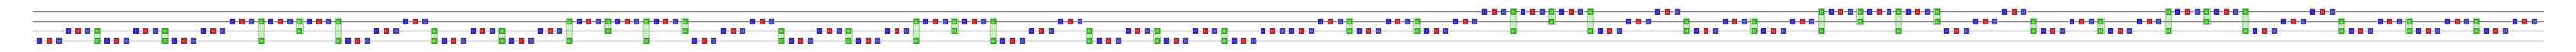

In [10]:
GLOBAL_IDENTITY_LAYER_PARAMS_SU8=arch_optimise_to_zero(4)



okay so it looks like this works, i made su8 layers and they were able to replicate the identity. I should check now that the gate is indeed able to cover all of su8.

In [27]:
def arch_optimise_su8_gate_to_target(targ,eps: float = 1e-2):
    """optimisies to a target not just identity, targ is a numpy array from su8 which is the target"""
    #DIY SU8 as no inbuilt SU8
    qc = qtn.Circuit(3)
    params=eps*np.random.standard_normal(size=(111))
    arch_apply_su8(qc,0,params)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(targ.reshape(2,2,2,2,2,2),inds=('k0','k1','k2','b0','b1','b2')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['R'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()
    #Need to take out the params I want
    ordered_params = []
    for k in sorted(params):
        v = params[k]
        # keep only scalar parameters (SU2 angles)
        if isinstance(v, np.ndarray) and v.shape == (1,):
            ordered_params.append(v.item())

    ordered_params = np.array(ordered_params)
    return ordered_params

def random_su8():
    """
    Generate a random SU(8) matrix.

    Returns
    -------
    U : np.ndarray
        8x8 unitary matrix with determinant 1.
    """
    # 1. random complex 8x8
    X = np.random.randn(8, 8) + 1j * np.random.randn(8, 8)

    # 2. Orthonormalize columns using QR decomposition
    Q, R = np.linalg.qr(X)

    # 3. Adjust determinant to 1
    det_Q = np.linalg.det(Q)
    U = Q / det_Q**(1/8)
    print("CHECK SU8 CONSTRUCTION:")
    print("Determinant=",np.linalg.det(U))
    print("Udagger U:",np.round(U.conj().T @ U))
    print("U=",np.round(U,2))

    return U


In [29]:
targparams=arch_optimise_su8_gate_to_target(random_su8())

CHECK SU8 CONSTRUCTION:
Determinant= (1+5.551115123125784e-17j)
Udagger U: [[ 1.-0.j -0.-0.j -0.+0.j  0.+0.j  0.+0.j -0.-0.j  0.+0.j -0.-0.j]
 [-0.+0.j  1.-0.j  0.+0.j -0.+0.j -0.-0.j -0.+0.j -0.-0.j  0.+0.j]
 [-0.-0.j  0.-0.j  1.-0.j -0.+0.j  0.+0.j  0.+0.j -0.+0.j  0.+0.j]
 [ 0.-0.j -0.-0.j -0.-0.j  1.-0.j -0.-0.j  0.+0.j  0.+0.j -0.-0.j]
 [ 0.-0.j -0.+0.j  0.-0.j -0.+0.j  1.+0.j  0.+0.j  0.+0.j -0.-0.j]
 [-0.-0.j -0.-0.j  0.-0.j  0.-0.j  0.-0.j  1.+0.j  0.+0.j -0.-0.j]
 [ 0.-0.j -0.+0.j -0.-0.j  0.+0.j  0.-0.j  0.-0.j  1.+0.j  0.+0.j]
 [ 0.+0.j  0.-0.j  0.-0.j -0.+0.j  0.+0.j -0.+0.j  0.-0.j  1.+0.j]]
U= [[-0.22-0.13j  0.36+0.15j  0.05+0.17j -0.59-0.19j -0.11-0.35j  0.1 +0.12j
  -0.16-0.19j -0.25+0.29j]
 [-0.35-0.01j -0.16+0.13j -0.37+0.61j  0.12+0.34j -0.04-0.13j  0.22-0.17j
   0.18+0.11j -0.18-0.14j]
 [-0.01+0.31j -0.08-0.25j -0.29+0.2j   0.04-0.49j  0.13+0.26j  0.2 -0.17j
  -0.4 +0.22j -0.03+0.32j]
 [-0.4 +0.34j -0.27-0.01j  0.11-0.37j  0.01-0.11j -0.07-0.27j -0.04+0.21j
   0.27+

+0.000000000000 [best: +0.000000000000] :  37%|███▋      | 221/600 [00:41<01:11,  5.33it/s]


Yippee!! Looks like this does indeed cover all of su8! This is great, I'll run this a through times and just see how it goes.

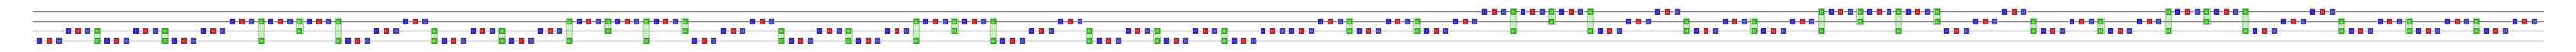

In [36]:
circ=arch_near_zero_parametrized_circ_layer(4)

In [40]:
circ.psi.to_dense()

array([[ 1.22816272e-07-1.00000000e+00j],
       [ 4.05869780e-07-7.60590081e-08j],
       [ 5.79592660e-07-2.94802405e-08j],
       [ 2.41947986e-07+7.15202228e-08j],
       [ 4.03503762e-07+2.83003569e-09j],
       [ 3.38036845e-07-4.06609353e-08j],
       [ 7.41059687e-08+1.00850577e-07j],
       [ 1.12224296e-07+9.75545900e-08j],
       [ 2.29781189e-07-4.37488229e-08j],
       [ 4.91147038e-14+1.41864625e-13j],
       [ 3.38036737e-07-4.06606790e-08j],
       [ 2.55679428e-14+1.49808569e-13j],
       [-1.67842181e-07+2.93305350e-08j],
       [ 9.87776699e-14+3.38387265e-14j],
       [ 1.12224197e-07+9.75546718e-08j],
       [ 2.16783557e-14+1.40343918e-13j]])

This is good! This shows that the near_zero_parametise_circ_layers indeed works and acts as the identity (up to global phase). Now will do the next step, the "optimise_circ_layers".

In [ ]:
#CAREFUL USING THIS ONE! THE ONE I USE IS LATER DOWN BUT KEEPING THIS HERE JUST IN CASE
def arch_optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()

    circ = arch_near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()


    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                #HERE I MAY NEED TO ADD AN ADDITION TO FIX THE WHOLE PARAMS FROM CNOT ERROR THAT CAN OCCUR. or could be done after if i really need the params.
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        print(f'At init net entropy comp = {torch_schmidt_entropy_loss(to_opt.copy(),init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(to_opt.copy(),init_mps.copy())}')
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['R'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['R'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            print(f'After opt: net entropy comp = {torch_schmidt_entropy_loss(best_copy,init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(best_copy,init_mps.copy())}')

        return best_layer_tn
    else:
        return opt_layer_tn

('_e4abeaAAAKU', '_e4abeaAAAKT')


IndexError: list index out of range

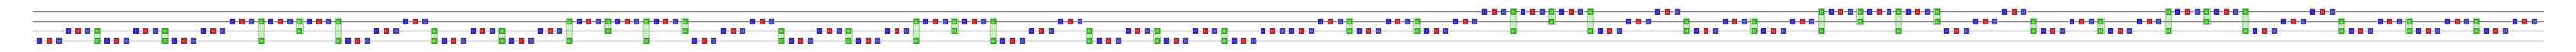

In [6]:
vector=np.random.rand(2**4)
current_mps=qtn.MatrixProductState.from_dense(vector)/qtn.MatrixProductState.from_dense(vector).norm()
current_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
current_mps.gauge_all(method='simple',inplace=True)
arch_optimise_circ_layer(current_mps, loss = arch_chi4_torch_schmidt_loss_fn , verbose=True)

okay so here I need to fix the issue with the index not being right. check what type of object the alleged layer is as i think mps must have specifc layers. as a matter of fact I think that the code the josh's have expects to get an mpsand that is whythey seach for the b to replace with the I.

In [13]:
GLOBAL_IDENTITY_LAYER_PARAMS=optimise_to_zero(4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   9%|▉         | 53/600 [00:01<00:11, 49.07it/s]


In [19]:
def apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    #Archie working out how it all works here
    print("mps (The target)")
    mps.draw()
    print(type(mps))
    print("the layer")
    circ_tn.draw()
    print(type(circ_tn))
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        print(t.inds)
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))

    if gauge:
        new.gauge_all(method='simple',inplace=True)
    
    """to_split = new.tensors[-1]
    num_phys = [i for i in to_split.inds if i.startswith('b')]
    if len(num_phys)>1:
        left_phys_idx = new.L-2
        virt = [i for i in to_split.inds if not i.startswith('b')][0]
        TL,TR = to_split.split(
            left_inds=(f'b{left_phys_idx}',virt),
            right_inds=(f'b{left_phys_idx+1}'),
            method='svd',
            absorb='both'
        )

        TL.add_tag(f"I{left_phys_idx}")
        TR.drop_tags()
        TR.add_tag(f"I{left_phys_idx+1}")
        new = qtn.TensorNetwork([new.tensors[:-1],TL,TR])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)"""

    return new

mps (The target)


c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


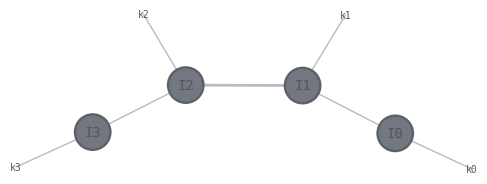

<class 'quimb.tensor.tensor_1d.MatrixProductState'>
the layer


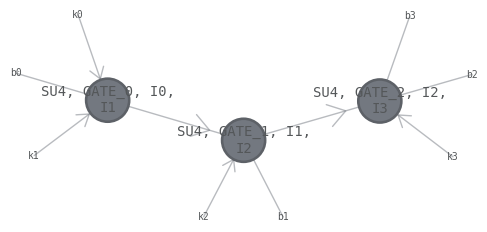

<class 'quimb.tensor.tensor_arbgeom.TensorNetworkGenOperator'>
('_e4abeaAAAfZ', 'b0')
('b1', '_e4abeaAAAfb', '_e4abeaAAAfZ')
('b2', 'b3', '_e4abeaAAAfb')


In [28]:
#See how Josh's code works, with a normal layer that they would add.

# Random MPS as 
np.random.seed(42)
rand_vector=np.random.rand(2**4) 
rand_mps = qtn.MatrixProductState.from_dense(rand_vector)/qtn.MatrixProductState.from_dense(rand_vector).norm()
rand_mps.apply_to_arrays(lambda x: torch.as_tensor(x))

#Building circuit layer (must be fine as this is what they have in optimiser)
circ=near_zero_parametrized_circ_layer(4)
layer = circ.uni #turn into tensor network form
layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
to_opt = layer.copy()

rand_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
to_opt.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

new=apply_single_layer(circ_tn=to_opt,mps=rand_mps)

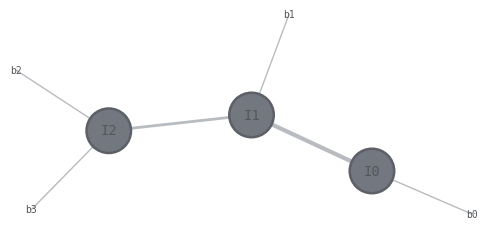

In [29]:
new.draw()

now I will try and get mine working, with my (potentially difficult) su8 layer

In [60]:
def arch_apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of su8 unitaries to evolve an MPS.
    """
    #Archie working out how it all works here
    '''
    print("mps (The target)")
    mps.draw()
    print(type(mps))
    print("the layer")
    circ_tn.draw()
    print(type(circ_tn))
    print("contracting layer")
    circ_tn = circ_tn.contract(all)
    circ_tn.draw()
    '''
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    '''THIS IS THE OLD INDEX CHANGER DONT THINK I NEED IT NOW THAT WE HAVE BIG MPS
    for t in new:
        print(t.inds)
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))
    '''

    if gauge:
        new.gauge_all(method='simple',inplace=True)

    # Restore back to an mps
    new_mps=qtn.MatrixProductState.from_dense(new.to_dense())
    return new_mps

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


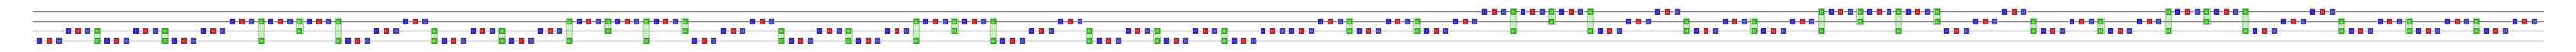

In [61]:
#ow try ading my own layer.

# Random MPS as 
np.random.seed(42)
rand_vector=np.random.rand(2**4) 
rand_mps = qtn.MatrixProductState.from_dense(rand_vector)/qtn.MatrixProductState.from_dense(rand_vector).norm()
rand_mps.apply_to_arrays(lambda x: torch.as_tensor(x))

#Building circuit layer of su8
circ=arch_near_zero_parametrized_circ_layer(4)
layer = circ.uni #turn into tensor network form
layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
to_opt = layer.copy()

rand_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
to_opt.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

new=arch_apply_single_layer(circ_tn=to_opt,mps=rand_mps)

In [63]:
new

MatrixProductState(tensors=4, indices=7, L=4, max_bond=4)

okay cool well this finally seems to be working. Now time to see if it works with the optimse circ layers.

In [ ]:
def arch_optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()

    circ = arch_near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()


    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                #HERE I MAY NEED TO ADD AN ADDITION TO FIX THE WHOLE PARAMS FROM CNOT ERROR THAT CAN OCCUR. or could be done after if i really need the params.
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['R'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['R'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            

        return best_layer_tn
    else:
        return opt_layer_tn
#Loss function
def arch_chi4_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=4 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2+p_3 + p_4)                   # tail mass (chi=4 infidelity)
      
      T_j drives you towards high chi=4 fidelity.
    
    """
    #INPUT IS OP, THE OPERATION WE WANT TO APPLY (SO THE LAYER), AND INIT IS THE STATE WE WANT TO HAVE THE OP APPLIED TO. G IS  A PARAMETER WE DONT REALLY NEED TO WORRY ABOUT AS IT IS SET TO 0, IT IS A RELIC OF A DIFFERENT LOSS FUNCITON.

    init_tn = init_tn.copy()
    op = op.copy()

    #THIS APPLIIES THE OPERATOR TO THE TENSOR NETWORK WE WANT USING MY METHOD
    
    init_tn.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    op.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
    new_tn = arch_apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    #Loops over each bond (internal index) and collects the sum of the tail from each bond
    for ind in new_tn.inner_inds():
        # λ^2 already, and this will give a list of all the squared schmidt coeffs at each internal bond
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        #if arent any here then will just skip the adding step
        if lam2.numel() == 0:
            continue
        
        #clamp stops numerial errors from negatives appearing that we dont want to exist
        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()  #the sum of all the schmidts at current bond we are looking at

        #eps is just a little numerical thingo to look after numerical instablisiltes
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
    
        # chi=4 tail mass
        topk = 4
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue
        vals.append(Tj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
C:\Users\archi\AppData\Local\Temp\ipykernel_17108\2155467923.py:118: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  init_tn.apply_to_arrays(lambda x: torch.tensor(x, dtype=torch.complex128, requires_grad=True))
C:\Users\archi\AppData\Local\Temp\ipykernel_17108\2155467923.py:119: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  op

initial loss = 0.0
Ensuring best parameters are retrieved...


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
  0%|          | 0/800 [00:00<?, ?it/s]


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

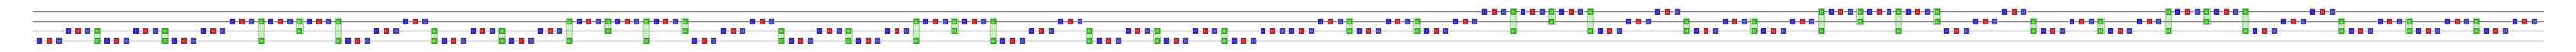

In [69]:
vector=np.random.rand(2**4)
current_mps=qtn.MatrixProductState.from_dense(vector)/qtn.MatrixProductState.from_dense(vector).norm()
current_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
current_mps.gauge_all(method='simple',inplace=True)
arch_optimise_circ_layer(current_mps, loss = arch_chi4_torch_schmidt_loss_fn , verbose=True)

### Loss function building and testing


#### Testing loss function and Truncaiton error

Here I want to test if the loss function is indeed an accurate representation of the trunction error. Mathematically I think this should be the case but I want to check with actual mps data, which is also a good stage to get comfortable with the utility of the loss function.

In [ ]:
#Loss function
def new_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.5,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=2 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2)                   # tail mass (chi=2 infidelity)
      r_i      = p_i / T_j for i >= 3             # tail distribution (if T_j > 0)
      H_tail   = -sum_{i>=3} r_i log2 r_i         # entropy of tail
      H_tail_n = H_tail / log2(d_tail) in [0,1]   # d_tail = len(tail), if >= 2

    Per-cut cost:
      C_j(g) = T_j * (1 + g * H_tail_n)

    - T_j drives you towards high chi=2 fidelity.
    - H_tail_n only cares about *how messy the tail is*.
    - g in [0,1] controls how much you value "cleaning up / structuring the tail"
      vs purely greedy chi=2.

    When T_j -> 0, C_j -> 0 regardless of H_tail_n, so late stages are effectively greedy.
    """
    #INPUT IS OP, THE OPERATION WE WANT TO APPLY (SO THE LAYER), AND INIT IS THE STATE WE WANT TO HAVE THE OP APPLIED TO. G IS  A PARAMETER WE DONT REALLY NEED TO WORRY ABOUT AS IT IS SET TO 0, IT IS A RELIC OF A DIFFERENT LOSS FUNCITON.
    # clamp g to [0, 1]
    #g = float(max(0.0, min(1.0, g)))

    init_tn = init_tn.copy()
    op = op.copy()

    #THIS APPLIIES THE OPERATOR TO THE TENSOR NETWORK WE WANT
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    #Loops over each index and collects the sum of the tail from each bond
    for ind in new_tn.inner_inds():
        # λ^2 already
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if lam2.numel() == 0:
            continue
        
        #clamp stops numerial errors from negatives appearing that we dont want to exist
        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()

        #eps is just a little numerical thingo to look after numerical instablisiltes
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
        d = p_sorted.numel()

        if d <= 2:
            # no tail -> already rank<=2 across this cut
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        # chi=2 tail mass
        topk = 2
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        tail = p_sorted[topk:]          # shape (d_tail,)
        # numel is number of elements in a tensor
        d_tail = tail.numel() 

        #All of this is the tail entropy i dont care about, can remove this later
        if d_tail <= 1:
            # a single tail mode still present: no entropy structure
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            # tail distribution r_i = p_i / T_j
            r = tail / Tj
            r = torch.clamp(r, min=eps)

            H_tail = - (r * (r.log() / math.log(2.0))).sum()
            H_max = math.log2(d_tail)
            H_tail_norm = H_tail / H_max

        # multiplicative planning: penalise large & messy tails
        Cj = Tj * (1.0 + g * H_tail_norm)
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()

In [ ]:
# Random MPS
np.random.seed(42)
rand_vector=np.random.rand(2**6) 
rand_mps = qtn.MatrixProductState.from_dense(rand_vector)/qtn.MatrixProductState.from_dense(rand_vector).norm()
rand_mps

MatrixProductState(tensors=6, indices=11, L=6, max_bond=8)

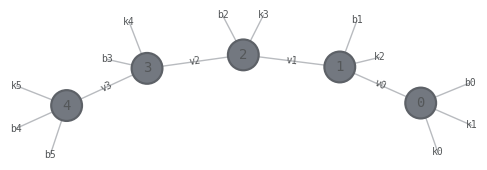

In [22]:
#Make an identity mps
def two_qubit_identity_layer(n_qubits):
    """
    Returns a TN layer of 2-qubit identity gates acting on neighboring qubits.
    """
    tensors = []
    for i in range(0, n_qubits - 1, 1):
        eye4 = np.eye(4).reshape(2,2,2,2)  # 2-qubit identity
        if i==0:
            tensors.append(qtn.Tensor(
            data=eye4,
            inds=(f'k{i}', f'k{i+1}', f'b{i}', f'v{i}'),
            tags={f'{i}'}
        ))
        elif i==n_qubits-2:
            tensors.append(qtn.Tensor(
            data=eye4,
            inds=(f'v{i-1}', f'k{i+1}', f'b{i}', f'b{i+1}'),
            tags={f'{i}'}
        ))
        else:
            tensors.append(qtn.Tensor(
            data=eye4,
            inds=(f'v{i-1}', f'k{i+1}', f'b{i}', f'v{i}'),
            tags={f'{i}'}
        ))
    return qtn.TensorNetwork(tensors)
idlayer=two_qubit_identity_layer(6)
idlayer.draw(show_inds='all',show_tags=True)

In [23]:
type(idlayer)

quimb.tensor.tensor_core.TensorNetwork

In [160]:
new =  idlayer| rand_mps

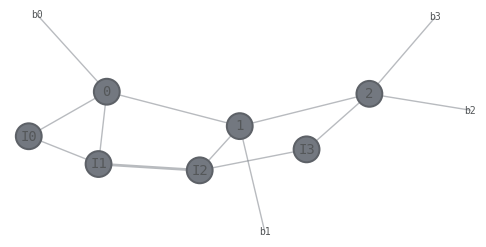

In [161]:
new.draw()

In [162]:
shared = qtn.bonds(idlayer, rand_mps)

for ix in shared:
    new.contract_ind(ix)


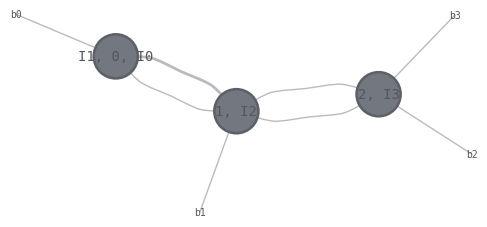

In [163]:
new.draw()

In [164]:
new.fuse_multibonds(inplace=True)

TensorNetwork(tensors=3, indices=6)

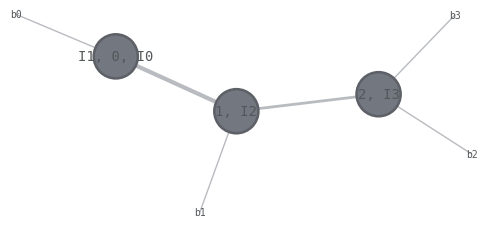

In [165]:
new.draw()

In [166]:
new.contract(all).data.reshape(-1)

array([0.44830575, 0.069045  , 0.35446771, 0.22755049, 0.23406364,
       0.29728579, 0.33495495, 0.09284629, 0.21969169, 0.4593376 ,
       0.11624028, 0.09435156, 0.22925081, 0.08866989, 0.00465954,
       0.10362818])

In [167]:
rand_mps.contract(all).data.reshape(-1)

array([0.44830575, 0.069045  , 0.35446771, 0.22755049, 0.23406364,
       0.29728579, 0.33495495, 0.09284629, 0.21969169, 0.4593376 ,
       0.11624028, 0.09435156, 0.22925081, 0.08866989, 0.00465954,
       0.10362818])

cool so this works for adding an identtity layer! Now need to test the rest of the add layer and see what it does, plus then see if the loss and the truncation matches.

In [168]:
new.view_as(qtn.MatrixProductState, inplace=True, L=rand_mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)


MatrixProductState(tensors=3, indices=6, L=4, max_bond=8)

In [169]:
new.gauge_all(method='simple',inplace=True)

MatrixProductState(tensors=3, indices=6, L=4, max_bond=4)

okay so the gauge does the whole get rid of unecessary bond things, i think this is kind of like my idea of converting to a vector then rexxpressing as an exact mps.

In [189]:
idlayer.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
rand_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

In [171]:
new_torch_schmidt_loss_fn(
    op=idlayer,
    init_tn=rand_mps,
    g=0
)

tensor(0.0384, dtype=torch.float64)

okay note that an issue has happened where the new mps is not really an mps so be careful as tensors have merged from the layer applicatoin, should be able to work aroudn this tho.

In [172]:
trunc_rand_mps=rand_mps.copy()
trunc_rand_mps.compress(max_bond=2)

In [174]:
np.abs((trunc_rand_mps.H | rand_mps).contract(all))

C:\Users\archi\AppData\Local\Temp\ipykernel_26132\1842909397.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  np.abs((trunc_rand_mps.H | rand_mps).contract(all))


tensor(0.9616, dtype=torch.float64)

In [178]:
rand_mps.inner_inds()

('_7ea499AAAGa', '_7ea499AAAGb', '_7ea499AAAGc')

In [179]:
rand_mps

MatrixProductState(tensors=4, indices=7, L=4, max_bond=4)

In [182]:
schmidt_coeffs_from_ind(rand_mps, "_7ea499AAAGa").to(torch.float64)

tensor([0.8199, 0.1801], dtype=torch.float64)

cool so this works yay!

#### Archie's Chi=4 loss function

In [ ]:
#Loss function GO ABOVE THIS ONE AS THIS ONE DOES NOT HAVE HTE REQUIRED ARCH TO ARRAYS IN IT
def arch_chi4_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=4 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2+p_3 + p_4)                   # tail mass (chi=4 infidelity)
      
      T_j drives you towards high chi=4 fidelity.
    
    """
    #INPUT IS OP, THE OPERATION WE WANT TO APPLY (SO THE LAYER), AND INIT IS THE STATE WE WANT TO HAVE THE OP APPLIED TO. G IS  A PARAMETER WE DONT REALLY NEED TO WORRY ABOUT AS IT IS SET TO 0, IT IS A RELIC OF A DIFFERENT LOSS FUNCITON.

    init_tn = init_tn.copy()
    op = op.copy()

    #THIS APPLIIES THE OPERATOR TO THE TENSOR NETWORK WE WANT
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    #Loops over each bond (internal index) and collects the sum of the tail from each bond
    for ind in new_tn.inner_inds():
        # λ^2 already, and this will give a list of all the squared schmidt coeffs at each internal bond
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        #if arent any here then will just skip the adding step
        if lam2.numel() == 0:
            continue
        
        #clamp stops numerial errors from negatives appearing that we dont want to exist
        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()  #the sum of all the schmidts at current bond we are looking at

        #eps is just a little numerical thingo to look after numerical instablisiltes
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
    
        # chi=4 tail mass
        topk = 4
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue
        vals.append(Tj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()

In [190]:
arch_chi4_torch_schmidt_loss_fn(
    op=idlayer,
    init_tn=rand_mps
)

tensor(0.0545, dtype=torch.float64)

In [191]:
trunc_rand_mps=rand_mps.copy()
trunc_rand_mps.compress(max_bond=4)
1-np.abs((trunc_rand_mps.H | rand_mps).contract(all))

C:\Users\archi\AppData\Local\Temp\ipykernel_26132\4255586133.py:3: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  1-np.abs((trunc_rand_mps.H | rand_mps).contract(all))


tensor(0.0545, dtype=torch.float64)

Cool so this works! We have got a loss function that tells you the error squared. IMPORTANT MATHS NOTE!! In the code Josh uses the squared inner product as there you have a normalised mps. Here it is not normalised so you dont need to square the overlap. squaring the overlap is a way of accounting for normalisation (see book).

### Printing Schmidt coefficient graphs as function runs. IGNORE THIS

Here I have made a main loop that will also log the schmidts and not just print them as it goes. WE DONT WANT THIS, WE WANT TO COLLECT DATA AT THE END AND PRINT THAT!

THe arch_opitmise... is the same as normal but it will return the fidelity of the bond 4 data rather than the bond 2 fidelity.

In [26]:
def arch_optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    #Puts the current MPS into a torch compatible object
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []
    approx_states = []
    schmidts_list=[]

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        
        schmidts=schmidt_coeffs_from_ind(targ_mps,ind)
        schmidts_list.append(schmidts)
        print(f'2. Central schmidt coefficients = {schmidts}')

        print(f'Central schmidt coefficients (first 32)')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 8 = {test_bond_accuracy(targ_mps,8)}')
    bond4 = [test_bond_accuracy(targ_mps,4)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        #OMGGGGG THIS IS THE ONE!!! THIS IS WHAT I NEED TO GET THE IMAGE!!
        print(f'Returning current approx state...')
        targ = targ_mps.copy()
        disentangled_state = new_mps.copy()            
        targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        fidelity = test_circuit_fidelity(targ, new_mps, param_set)
        print(f'True fidelity after reconstruction (should match bond 2) = {fidelity}')
        current_approx_state=reconstruct_circuit(disentangled_state,param_set)
        current_approx_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        current_approx_state.contract(all)
        current_approx_state/=current_approx_state.norm()
        approx_states.append(current_approx_state)
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            schmidts=schmidt_coeffs_from_ind(test,ind)
            schmidts_list.append(schmidts)
            print(f'2. Central schmidt coefficients = {schmidts}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            #BELOW JUST MAKES A MPS STATE THAT IS THE ZERO STATE, WITH THE SAME NUMBER OF TENSORS AS THE MAX BOND OF THE NEW MPS!!
            #THIS IS CURRENT STATE NOT CURRENT MPS SO CHILL
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond4.append(test_bond_accuracy(test,4))
        #swapped this to adding a new_mps.copy() 
        mps_states.append(new_mps.copy())

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond4,approx_states,schmidts_list

In [6]:
np.random.seed(42)
rand_vector=np.random.rand(2**6) 
target_mps = qtn.MatrixProductState.from_dense(rand_vector)/qtn.MatrixProductState.from_dense(rand_vector).norm()
target_mps

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(


MatrixProductState(tensors=6, indices=11, L=6, max_bond=8)

With my loss function..

In [21]:
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = arch_chi4_torch_schmidt_loss_fn # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states,schmidt_list = arch_optimise_sequential_layers(target_mps.copy(),num_layers=4,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  10%|█         | 63/600 [00:02<00:25, 21.20it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([0.8125, 0.0895, 0.0610, 0.0369], dtype=torch.float64)
Central schmidt coefficients (first 32)
Central purity (renyi-2 anti-entropy) = 0.6732821149403335
 bond 2 = 0.8277241844655298
 bond 4 = 0.9599305935105614
 bond 8 = 1.0000000000000009

 LAYER 0
initial loss = 0.3103654587990424
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.87871619 0.22707339 0.71998724 0.95575314]
New tail entropy term = 2.7815299648980187
tensor([4.1253e-12, 7.2732e-02, 1.3968e-01, 9.7956e-02], dtype=torch.float64)
At init net entropy comp = 3.5367565049134018 // tail loss = 0.3103654587990424


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.115659653714 [best: +0.115659653714] :  70%|███████   | 561/800 [01:21<00:34,  6.85it/s]


...

+0.004229697685 [best: +0.004229682847] :  60%|█████▉    | 476/800 [01:26<00:59,  5.48it/s]



 LAYER 3
initial loss = 0.007740036006728457
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.51386323 0.28105043 0.62613729 0.96817383]
New tail entropy term = 2.3892247730186247
tensor([2.5364e-12, 3.3283e-03, 2.8123e-03, 1.5994e-03], dtype=torch.float64)
At init net entropy comp = 0.7967194512370006 // tail loss = 0.007740036006728457


+0.002510120250 [best: +0.002510120250] : : 1277it [02:52,  7.39it/s]                      


final loss = 0.003042132314762913
best val = 0.002510120249762271. Final loss = 0.003042132314762913
after updating, final loss = 0.002510120249762271
Tail entropy (normalised) per cut: [0.66298538 0.23117513 0.59083766 0.81772794]
New tail entropy term = 2.302726118114947
tensor([1.7681e-12, 9.6572e-04, 1.1014e-03, 4.4296e-04], dtype=torch.float64)
After opt: net entropy comp = 1.1570685386281745 // tail loss = 0.002510120249762271
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9984043199928608
 error from singular value truncation ~ (2.6951343549797002e-05+3.144271042537044e-18j), cut from max bond 8 to 5. sv cutoff = 0.0001
 new max bond = 5
norm = (0.9999999999999998+2.0166160408230386e-17j)
2. Central schmidt coefficients = tensor([9.2317e-01, 7.6436e-02, 3.0557e-04, 8.7908e-05], dtype=torch.float64)
 bond 2 = 0.9986235665452953
 bond 4 = 0.9998770917771658
 bond 6 = 0.9999999999999991
optimising for chi=2 approx:


+0.001375578748 [best: +0.001375576821] :  66%|██████▌   | 528/800 [01:29<00:46,  5.89it/s]


In [ ]:
print(approx_states)
print(param_set)
print([t.tolist() for t in schmidt_list])
print(fid2_archopt)


[[0.8125127995470441, 0.0895334955774166, 0.06104653659612281, 0.03690716829398311], [0.8360329603042139, 0.146161671051725, 0.01130098763198954, 0.006504381020074082], [0.828792466477109, 0.16737447544146977, 0.002874475882200422, 0.0009585822072197098], [0.9620139181979099, 0.03753563427401231, 0.0002846278441291125, 0.0001658196919504047], [0.9611914103474805, 0.03869382429120857, 0.00011476536731331281]]
[0.9599305935105614, 0.9927828683211798, 0.9974176206926354, 0.9997995145185532, 1.0000000000000009]
[TensorNetwork(tensors=11, indices=21), TensorNetwork(tensors=16, indices=31), TensorNetwork(tensors=21, indices=41), TensorNetwork(tensors=26, indices=51)]
[{6: array([ 1.9006971 ,  2.20307915,  1.64083343, -1.17971448, -0.36206633,
       -2.23537165,  0.0445739 ,  0.1233273 ,  0.5231353 , -1.37444134,
       -0.66473217, -0.39796256,  1.69640222, -2.39899953,  3.65738736]), 7: array([-0.183158  ,  0.98016554,  0.9125469 , -0.99246844,  0.04986436,
       -0.76901939,  0.1421383 ,

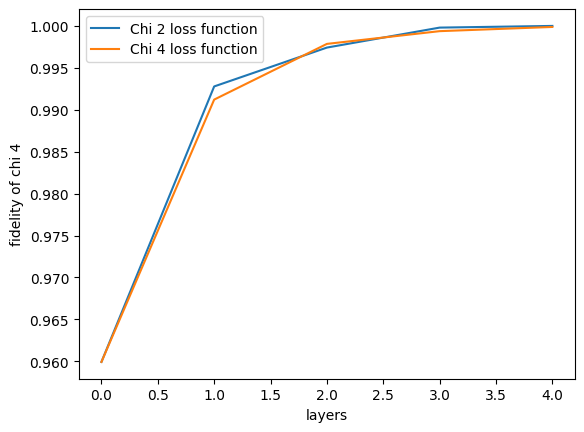

In [25]:
chi2=[0.9599305935105614, 0.9927828683211798, 0.9974176206926354, 0.9997995145185532, 1.0000000000000009]
chi4=[t.tolist() for t in fids]
x = range(len(chi2))
plt.plot(x, chi2, label="Chi 2 loss function")
plt.plot(x, chi4, label="Chi 4 loss function")

plt.xlabel("layers")
plt.ylabel("fidelity of chi 4")
plt.legend()
plt.show()

With new loss function...

c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\quimb\tensor\optimize.py:632: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(x).to(self.device)


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  10%|▉         | 59/600 [00:02<00:27, 19.78it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([0.8125, 0.0895, 0.0610, 0.0369], dtype=torch.float64)
Central schmidt coefficients (first 32)


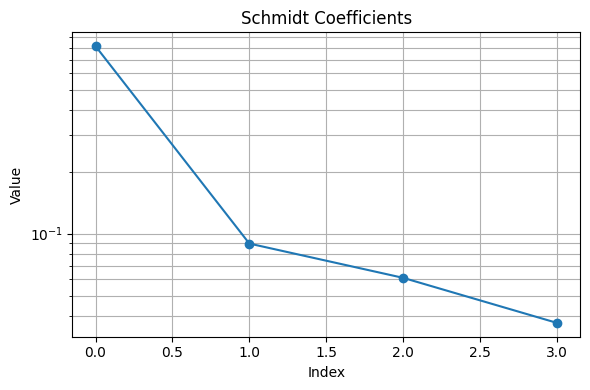

Central purity (renyi-2 anti-entropy) = 0.6732821149403335
 bond 2 = 0.8277241844655298
 bond 4 = 0.9599305935105614
 bond 8 = 1.0000000000000009

 LAYER 0
initial loss = 0.31034842240404914
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.87870395 0.22701532 0.71978888 0.95581463]
New tail entropy term = 2.781322775172376
tensor([4.1254e-12, 7.2711e-02, 1.3967e-01, 9.7965e-02], dtype=torch.float64)
At init net entropy comp = 3.536649123984594 // tail loss = 0.31034842240404914


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\anaconda3\envs\newMPS\Lib\site-packages\scipy\optimize\_basinhopping.py:298: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.106278273369 [best: +0.106278273369] :  95%|█████████▌| 763/800 [01:51<00:05,  6.86it/s]


final loss = 0.10627827336948492
best val = 0.10627827336948492. Final loss = 0.10627827336948492
after updating, final loss = 0.10627827336948492
Tail entropy (normalised) per cut: [0.87790207 0.10658065 0.60740501 0.88321879]
New tail entropy term = 2.4751065060896273
tensor([4.2442e-12, 5.2461e-02, 3.9720e-02, 1.4097e-02], dtype=torch.float64)
After opt: net entropy comp = 2.776034486187604 // tail loss = 0.10627827336948492
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9344454768095998


C:\Users\archi\AppData\Local\Temp\ipykernel_492\71621303.py:1401: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2


 error from singular value truncation ~ (1.467200045002226e-05+2.081698713856635e-17j), cut from max bond 8 to 7. sv cutoff = 0.0001
 new max bond = 7
norm = (1.0000000000000004+6.938893903907225e-18j)
2. Central schmidt coefficients = tensor([0.8411, 0.1449, 0.0098, 0.0042], dtype=torch.float64)
Central schmidt coefficients (first 32)


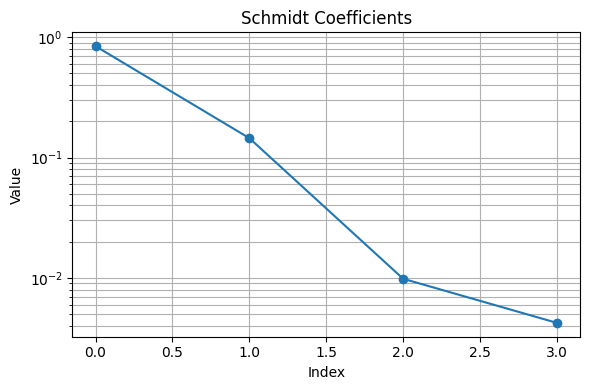

 bond 2 = 0.9344710413815834
 bond 4 = 0.9932021235275489
 bond 6 = 0.999744593909985
optimising for chi=2 approx:


+0.062576777947 [best: +0.062576744316] :  53%|█████▎    | 425/800 [01:25<01:15,  4.95it/s]



 LAYER 1
initial loss = 0.10624043369767511
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.81368771 0.11298734 0.60498616 0.88428024]
New tail entropy term = 2.415941454847962
tensor([3.7017e-12, 5.2450e-02, 3.9727e-02, 1.4064e-02], dtype=torch.float64)
At init net entropy comp = 2.7753026431360763 // tail loss = 0.10624043369767511


+0.023024961588 [best: +0.023024307540] : : 828it [02:00,  6.88it/s]                       


final loss = 0.023024307539696864
best val = 0.023024307539696864. Final loss = 0.023024307539696864
after updating, final loss = 0.023024307539696864
Tail entropy (normalised) per cut: [0.79624836 0.25804669 0.69758123 0.9975063 ]
New tail entropy term = 2.7493825777646137
tensor([3.7176e-12, 1.1115e-02, 8.8228e-03, 3.0866e-03], dtype=torch.float64)
After opt: net entropy comp = 2.4233960500810747 // tail loss = 0.023024307539696864
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9864985864783362
 error from singular value truncation ~ (1.0660656531991108e-06+5.551121040985261e-17j), cut from max bond 8 to 7. sv cutoff = 0.0001
 new max bond = 7
norm = (0.9999999999999992-5.551115123125788e-17j)
2. Central schmidt coefficients = tensor([0.8724, 0.1245, 0.0016, 0.0015], dtype=torch.float64)
Central schmidt coefficients (first 32)


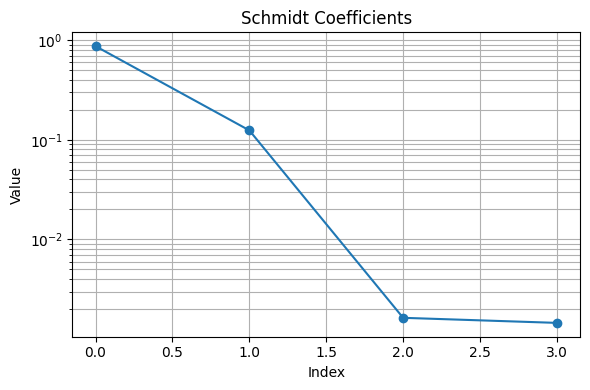

 bond 2 = 0.9864866069954956
 bond 4 = 0.9981719091495114
 bond 6 = 0.9997086918256076
optimising for chi=2 approx:


+0.017677951807 [best: +0.017677951807] :   7%|▋         | 54/800 [00:11<02:46,  4.48it/s]

In [ ]:
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = arch_chi4_torch_schmidt_loss_fn

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=4,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)